# Inland Excess Water (IEW) Monitoring — SSL4EO-S12 ViT + Terrain UPerNet

**Notebook 14. Notebook 12's recipe with a stronger, transformer-based pre-trained encoder.**

### Why this notebook

Notebook 12 (ResNet-50 encoders + terrain) is the best model so far: test macro-F1 78.62 and pixel-weighted F1 (classes 2–6) 84.12, against 76.53 / 81.53 for notebook 10 and the paper's 81.19. Its ablation showed where the gain comes from: the **pre-trained encoders**, the **terrain features** (zeroing them cost vegetation about 4 F1 points) and the **radar** (zeroing it cost the most). This notebook keeps all of that and changes one thing: **the encoder**.

| | Notebook 12 | **Notebook 14** |
|---|---|---|
| Optical encoder | ResNet-50, SSL4EO-S12 **MoCo** | **ViT-B/16, SSL4EO-S12 MAE** (ViT-S/16 selectable) |
| Radar encoder | ResNet-50, SSL4EO-S12 MoCo | **ViT-B/16, SSL4EO-S12 MAE** on Sentinel-1 |
| Encoder training | Whole ResNets after 2 frozen epochs | Frozen first, then only the **last 4 transformer blocks** |
| Terrain, fusion, decoder, heads, loss, protocol | as described in notebook 12 | **identical**, so any difference is the encoder |

A **masked autoencoder (MAE)** is trained to rebuild hidden image patches, on about 250 k Sentinel-1/2 locations worldwide. Transformers pre-trained this way carry global context (a patch "knows" what the rest of the 3.6 km window looks like), which a ResNet's local filters only approximate. That matters here because waterlogging depends on landscape position.

### Architecture

```
 S2 (11 bands, reflectance)  ──► ViT SSL4EO-S12 MAE (S2, 13-band weights: B9/B10 slices dropped, rescaled 13/11)
                                      tokens from blocks 3, 6, 9, 12  (1/16 resolution, 14 x 14 grid)
 S1 (VV, VH in dB, SSL4EO stats) ──► ViT SSL4EO-S12 MAE (S1)  same four taps
 Aux (15 ch: spectral indices, cloud score, validity flags, VV/VH ratio, 5 terrain features)
                                  ──► light CNN encoder  (1/4, 1/8, 1/16, 1/32)

 per scale: simple feature pyramid on each ViT (x4 up, x2 up, same, x1/2) -> concat(S2, S1, aux)
            -> 1x1 conv -> channel gate  (cross-modal fusion at 4 scales)
 UPerNet:   pyramid pooling + FPN -> 256 ch @ 1/4          ──► auxiliary head (deep supervision)
 detail:    CNN on all 28 input channels at 1/1 and 1/2 gives the fine boundaries a 16-px ViT cannot
 refine:    up x2 (+ 1/2 detail) -> up x2 (+ full-res detail + 1x1 spectral MLP)
 heads:     main (6)   coarse (4)   ordinal (2: P(>= moderate), P(serious | >= moderate))
```

### Training recipe (same family as notebooks 12 and 13)

| Item | Setting |
|---|---|
| Epochs 1…`FREEZE_EPOCHS` | Both ViTs completely frozen. Only the fusion, decoder, CNN branches and heads train. |
| Afterwards | The last `UNFREEZE_LAST_BLOCKS` blocks and final norm of **each** ViT train at `BACKBONE_LR` (20× smaller than `HEAD_LR`) |
| Loss | Ordinal-smoothed weighted CE + Dice + auxiliary head + coarse CE + ordinal BCE |
| Sampling | Class-aware patches, 224 px (a ViT with 16-px patches built for 224 px) |
| Weights for evaluation | EMA of the trainable weights |
| Inference | 224-px windows, central 160 px kept (32-px margin), flip test-time augmentation |
| Calibration | Held-out training scenes only, conservative (bias capped at ±1, used only if it gains ≥ 1 point) |

Checkpoints and the EMA copy store only the trainable part, so they stay small.

### Honest expectations

Notebook 12 already won on vegetation and slightly affected soil. A better encoder may add a few points there; **serious and moderate soil have stayed at 60–70 F1 in every model**, so do not expect those to jump. **90+ F1 on every class remains unlikely.** MAE features usually need some fine-tuning to become good segmentation features (that is why the last blocks are unfrozen), so if the result is below notebook 12, try `UNFREEZE_LAST_BLOCKS = 6` or `ENCODER = "small16"` before drawing conclusions.

### How to run

1. **Environment:** `pip install -U "torchgeo>=0.7" rasterio pyyaml matplotlib` with a CUDA build of PyTorch. The ViT-B/16 weights and the Sentinel-1 MAE weights arrived in torchgeo 0.7, and the version in the notebook 12 environment (0.5.2) does not have them. The first cell with the model prints the available weights if a name is missing.
2. **Internet once:** for the encoder weights (`ENCODER = "base16"` is about 2 × 330 MB) and, if the terrain files from notebook 12 are not present in `outputs/dem/`, the Copernicus DEM tiles. The notebook reuses `outputs/dem/*.npy` if they already exist.
3. **Dataset path:** `dataset_root` in `configs/data.yaml`.
4. **Dry run:** `QUICK_TEST = True`, run all cells; then set it to `False`, **restart the kernel** and run all cells. Stale outputs from a trial run stay in a notebook until the cells are re-run.
5. **Memory (6 GB GPU):** defaults are `BATCH_SIZE = 4`, `ACCUM_STEPS = 2`, ViT-B/16 with frozen early blocks. If you get *CUDA out of memory*, set `BATCH_SIZE = 2`, `ACCUM_STEPS = 4`, or `ENCODER = "small16"` (ViT-S/16, about a quarter of the weights).
6. **Interruptions:** training saves each epoch and resumes automatically.

This code has **not been executed** at the time of writing. Expect the dry run to show small fixes.

### Outputs

- `outputs/checkpoints/vit_best.pt`, `vit_last.pt`, `vit_calibration.json`
- `outputs/vit_results.json` (all test metrics, per-scene scores, ablation)
- `outputs/preds_vit/<scene>.npy` (predicted label maps: raw, blend, calibrated)

## 1. Imports and configuration

In [ ]:
# --- Kaggle / Colab Environment Setup ---
# Install required geospatial and foundation model packages
# NOTE: Make sure "Internet" is toggled to ON in Kaggle sidebar (Settings -> Internet)!
import sys
!{sys.executable} -m pip install -q "torchgeo>=0.7" rasterio pyyaml


In [ ]:
import os
os.environ['KMP_DUPLICATE_LIB_OK'] = 'TRUE'
os.environ['PROJ_NETWORK'] = 'OFF'

import contextlib
import json
import math
import time
import urllib.request
from pathlib import Path

import numpy as np
import yaml
import rasterio
from rasterio.windows import Window
from rasterio.warp import reproject, Resampling, transform_bounds
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

QUICK_TEST = False        # True = tiny dry run of the whole notebook (writes *_quicktest* files only)

SEED         = 0
PATCH        = 224          # fixed by the ViT (224-px pre-training); must equal TILE + 2 * MARGIN
GRID_STRIDE  = 56
BATCH_SIZE   = 4
ACCUM_STEPS  = 2            # effective batch = BATCH_SIZE * ACCUM_STEPS
NUM_WORKERS  = 2 if torch.cuda.is_available() else 0  # 2 on Linux/Kaggle GPU, 0 on Windows/CPU
USE_AMP      = True
RESUME       = True

ENCODER              = "base16"      # "base16" (ViT-B/16, 86M each) or "small16" (ViT-S/16, 22M each)
BACKBONE             = ENCODER
PRETRAINED           = True          # SSL4EO-S12 MAE weights via torchgeo (needs internet once)
USE_DEM              = True          # Copernicus 30 m terrain features (reuses outputs/dem/*.npy if present)
UNFREEZE_LAST_BLOCKS = 4
FREEZE_EPOCHS        = 3

EPOCHS            = 25
SAMPLES_PER_EPOCH = 2000
VAL_PATCHES       = 300
HEAD_LR           = 1e-3     # fusion, decoder, CNN branches, heads
BACKBONE_LR       = 5e-5     # unfrozen ViT blocks
WEIGHT_DECAY      = 0.05
WARMUP_FRAC       = 0.05
EMA_DECAY         = 0.999
ORDINAL_SMOOTH    = 0.10
GAIN_JITTER       = 0.05

TILE, MARGIN = 160, 32      # inference windows are exactly PATCH
INFER_BATCH  = 8
TTA          = "flip"       # "none" | "flip" | "d4" (d4 is 8x slower)

VAL_SCENES  = ["BNPI_20230208", "KNPI_20220310"]       # same as notebooks 10 to 13
CLASS_SHARE = {0: 0.05, 1: 0.20, 2: 0.20, 3: 0.10, 4: 0.10}

MAX_TILES = None
if QUICK_TEST:
    EPOCHS, FREEZE_EPOCHS, SAMPLES_PER_EPOCH, VAL_PATCHES = 2, 1, 16, 8
    TTA, MAX_TILES = "none", 4

assert ENCODER in ("base16", "small16"), "ENCODER must be 'base16' or 'small16'"
assert PATCH % 16 == 0 and PATCH == 224, "the pre-trained ViTs expect 224-px inputs"
assert TILE + 2 * MARGIN == PATCH, "TILE + 2*MARGIN must equal PATCH"

TAG       = "vit" + ("_quicktest" if QUICK_TEST else "")
CKPT_DIR  = Path("outputs/checkpoints")
CKPT_DIR.mkdir(parents=True, exist_ok=True)
BEST_PATH = CKPT_DIR / f"{TAG}_best.pt"
LAST_PATH = CKPT_DIR / f"{TAG}_last.pt"
CAL_PATH  = CKPT_DIR / f"{TAG}_calibration.json"
RESULTS_PATH = Path("outputs") / f"{TAG}_results.json"
PRED_DIR  = Path("outputs") / f"preds_{TAG}"
PRED_DIR.mkdir(parents=True, exist_ok=True)
DEM_DIR = Path("outputs/dem")
DEM_RAW = DEM_DIR / "raw"
DEM_RAW.mkdir(parents=True, exist_ok=True)

torch.manual_seed(SEED)
np.random.seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
AMP_ON = USE_AMP and device.type == "cuda"
AMP_DTYPE = torch.bfloat16 if (AMP_ON and torch.cuda.is_bf16_supported()) else torch.float16
if device.type == "cuda":
    torch.backends.cudnn.benchmark = True
    print(f"GPU: {torch.cuda.get_device_name(0)} | "
          f"{torch.cuda.get_device_properties(0).total_memory / 2**30:.1f} GB")
else:
    print("WARNING: No CUDA GPU detected! On Kaggle: open Settings in the right sidebar -> Accelerator -> select 'GPU T4 x2' or 'GPU P100'.")
print(f"PyTorch {torch.__version__} | device {device} | AMP {AMP_ON} ({AMP_DTYPE if AMP_ON else '-'})")


def autocast():
    return torch.autocast(device_type=device.type, dtype=AMP_DTYPE, enabled=AMP_ON)


def make_scaler():
    enabled = AMP_ON and AMP_DTYPE == torch.float16
    try:
        return torch.amp.GradScaler("cuda", enabled=enabled)
    except (AttributeError, TypeError):
        return torch.cuda.amp.GradScaler(enabled=enabled)


GPU: NVIDIA GeForce RTX 4050 Laptop GPU | 6.0 GB
PyTorch 2.6.0+cu124 | device cuda | AMP True (torch.bfloat16)


## 2. Data: scenes and per-pixel inputs

Same data pipeline as notebook 12, with one difference for the radar encoder: the ViT was pre-trained on Sentinel-1 backscatter in **dB, ordered VV then VH, normalised with the SSL4EO-S12 statistics** (mean −12.59 / −20.26, std 5.26 / 5.91). This dataset's first two S1 channels are the VV and VH backscatter, but their order is not documented, so the code identifies **VV as the channel with the higher mean** (VV is physically about 7 dB brighter than VH over land; the dataset means are −13.7 and −21.6). The optical encoder receives reflectance (DN / 10000), which is the scaling the SSL4EO-S12 optical weights expect.

Each sample has three inputs plus the label: `s2` (11 bands), `s1` (2 channels, SSL4EO-normalised), `aux` (15 channels: 6 spectral indices, cloud score, S2 valid flag, standardised VV/VH ratio, S1 valid flag, 5 terrain features).

In [30]:
import shutil

def locate_dataset_root() -> Path:
    """
    Auto-detect dataset root across Kaggle (/kaggle/input/dl-dataset),
    configs/data.yaml, and local directory structures.
    """
    kaggle_input = Path("/kaggle/input")
    if kaggle_input.exists():
        # 1. Check known candidate folders for dl-dataset
        for cand in [
            kaggle_input / "dl-dataset",
            kaggle_input / "dl-dataset" / "tifs",
            kaggle_input / "dl-dataset" / "tifs_FINAL",
            kaggle_input / "dl-dataset" / "dataset",
        ]:
            if cand.exists() and ((cand / "Train" / "S2").exists() or (cand / "tifs" / "Train" / "S2").exists()):
                return cand

        # 2. Search recursively in /kaggle/input for any folder containing Train/S2
        for s2_dir in sorted(kaggle_input.glob("**/Train/S2")):
            return s2_dir.parent.parent

        # 3. Check for any directory containing S2/*.tif with parent Train or Test
        for s2_dir in sorted(kaggle_input.glob("**/S2")):
            if s2_dir.parent.name in ("Train", "Test") and list(s2_dir.glob("*.tif")):
                return s2_dir.parent.parent

        # Default Kaggle fallback if dl-dataset folder is attached
        dl_cand = kaggle_input / "dl-dataset"
        if dl_cand.exists():
            return dl_cand

    # 4. Check configs/data.yaml if present
    cfg_file = Path("configs/data.yaml")
    if cfg_file.exists():
        try:
            with open(cfg_file, "r") as f:
                cfg = yaml.safe_load(f)
            p = Path(cfg.get("dataset_root", ""))
            if p.exists() and ((p / "Train" / "S2").exists() or (p / "tifs" / "Train" / "S2").exists()):
                return p
        except Exception:
            pass

    # 5. Check common local paths
    for cand in [
        Path("dataset"),
        Path("tifs"),
        Path("C:/E/S5/Deep_Learning/dataset/tifs_FINAL"),
        Path("d:/flood-segmentation-sentinel12/tifs"),
        Path("/Users/gprajwalpriyadarshan/Desktop/SEM5/DL/flood-segmentation-sentinel12/dataset"),
    ]:
        if cand.exists() and ((cand / "Train" / "S2").exists() or (cand / "tifs" / "Train" / "S2").exists()):
            return cand

    return Path("/kaggle/input/dl-dataset")

dataset_root = locate_dataset_root()
print(f"Dataset root: {dataset_root}")
assert dataset_root.exists(), (
    f"Dataset directory not found at: {dataset_root}\n\n"
    "On Kaggle: In the right sidebar, click '+ Add Input' -> search for 'kabilank07/dl-dataset' and add it.\n"
    "Locally: Make sure 'dataset_root' in configs/data.yaml points to your dataset folder."
)

IGNORE = 255
NUM_CLASSES = 6
CLASS_NAMES = [
    "Open surface water (raw 2)",
    "Soil seriously affected (raw 3)",
    "Soil moderately affected (raw 4)",
    "Soil slightly affected (raw 5)",
    "Vegetation affected (raw 6)",
    "Not affected (raw 7)",
]
GT_LUT = np.full(256, IGNORE, dtype=np.uint8)
for raw, cls in {2: 0, 3: 1, 4: 2, 5: 3, 6: 4, 7: 5}.items():
    GT_LUT[raw] = cls

# Band order: B01 B02 B03 B04 B05 B06 B07 B08 B8A B11 B12
S2_MEAN = np.array([0.0436, 0.0557, 0.0723, 0.0838, 0.1151, 0.1598,
                    0.1800, 0.1974, 0.2004, 0.2233, 0.1706], dtype=np.float32)
S2_STD  = np.array([0.0182, 0.0233, 0.0272, 0.0340, 0.0380, 0.0598,
                    0.0686, 0.0751, 0.0728, 0.0674, 0.0606], dtype=np.float32)
S1_MEAN = np.array([-21.6081, -13.6686, -8.0403], dtype=np.float32)
S1_STD  = np.array([3.4706, 3.0644, 2.5309], dtype=np.float32)

# Sentinel-1 radar encoder statistics (SSL4EO-S12): dB, order VV then VH
SSL_S1_MEAN = np.array([-12.59, -20.26], dtype=np.float32)
SSL_S1_STD  = np.array([5.26, 5.91], dtype=np.float32)
VV_IDX = int(np.argmax(S1_MEAN[:2]))      # VV is the brighter channel; the dataset's channel order is undocumented
VH_IDX = 1 - VV_IDX
print(f'S1 channels: VV = channel {VV_IDX}, VH = channel {VH_IDX} (VV has the higher dataset mean)')

N_DEM   = 5
AUX_CH  = 6 + 1 + 1 + 1 + 1 + N_DEM     # indices, cloud, S2 valid, VV/VH ratio, S1 valid, terrain
FULL_CH = 11 + 2 + AUX_CH               # inputs of the full-resolution refinement branch


def make_inputs(s2_raw: np.ndarray, s1_raw: np.ndarray, dem):
    """Raw window arrays -> s2 (11,h,w) reflectance, s1 (2,h,w) standardised, aux (15,h,w)."""
    s2 = s2_raw.astype(np.float32)
    v2 = np.isfinite(s2).all(0)
    s2 = np.nan_to_num(s2, nan=0.0, posinf=0.0, neginf=0.0) / 10000.0
    v2 &= s2.sum(0) > 0
    s2 = np.clip(s2, 0.0, 2.0) * v2[None]

    eps = 1e-6
    blue, green, red, nir, nir_n, swir1, swir2 = s2[1], s2[2], s2[3], s2[7], s2[8], s2[9], s2[10]
    indices = np.stack([
        (nir - red) / (nir + red + eps),            # NDVI
        (nir_n - swir1) / (nir_n + swir1 + eps),    # NDMI
        (green - nir) / (green + nir + eps),        # NDWI
        (green - swir1) / (green + swir1 + eps),    # MNDWI
        (swir1 - red) / (swir1 + red + eps),        # SWIR1-RED soil-moisture index
        (swir1 - swir2) / (swir1 + swir2 + eps),    # SWIR ratio
    ]) * 2.0
    cloud = np.clip((np.minimum(blue, red) - 0.10) / 0.20, 0.0, 1.0)

    s1 = s1_raw.astype(np.float32)
    v1 = np.isfinite(s1).all(0)
    s1 = np.nan_to_num(s1, nan=0.0, posinf=0.0, neginf=0.0)
    v1 &= np.abs(s1[0]) > 1e-6
    s1n = np.clip((s1 - S1_MEAN[:, None, None]) / S1_STD[:, None, None], -6.0, 6.0) * v1[None]
    vv_vh = s1[[VV_IDX, VH_IDX]]
    s1_pre = np.clip((vv_vh - SSL_S1_MEAN[:, None, None]) / SSL_S1_STD[:, None, None], -8.0, 8.0) * v1[None]

    h, w = s2.shape[1:]
    terrain = dem.astype(np.float32) if dem is not None else np.zeros((N_DEM, h, w), dtype=np.float32)
    f2, f1 = v2.astype(np.float32), v1.astype(np.float32)
    aux = np.concatenate([indices * f2[None], (cloud * f2)[None], f2[None], s1n[2:3], f1[None], terrain], axis=0)
    aux = np.clip(np.nan_to_num(aux, nan=0.0, posinf=6.0, neginf=-6.0), -6.0, 6.0)
    return s2.astype(np.float32), s1_pre.astype(np.float32), aux.astype(np.float32)


class Scene:
    """One acquisition. S2/S1 read by window; GT and terrain held in RAM."""

    def __init__(self, split: str, split_dir: Path, filename: str):
        self.name = Path(filename).stem
        self.split = split
        self.site = self.name.split("_")[0]
        self.s2_path = split_dir / "S2" / filename
        self.s1_path = split_dir / "S1" / filename
        self.gt_path = split_dir / "GT" / filename
        for p in (self.s1_path, self.gt_path):
            if not p.exists():
                raise FileNotFoundError(f"Missing file: {p}")
        with rasterio.open(self.s2_path) as src:
            self.H, self.W = src.height, src.width
            self.transform, self.crs, self.bounds = src.transform, src.crs, src.bounds
        self.dem = None              # (5,H,W) float16, filled in §3
        self._gt = None
        self._s2 = None
        self._s1 = None

    @property
    def gt(self) -> np.ndarray:
        if self._gt is None:
            with rasterio.open(self.gt_path) as src:
                raw = np.nan_to_num(src.read(1), nan=0.0)
            gt = GT_LUT[np.clip(raw, 0, 255).astype(np.uint8)]
            assert gt.shape == (self.H, self.W), f"GT size mismatch in {self.name}"
            self._gt = gt
        return self._gt

    def read(self, r: int, c: int, h: int, w: int):
        if self._s2 is None:
            self._s2 = rasterio.open(self.s2_path)
            self._s1 = rasterio.open(self.s1_path)
        win = Window(c, r, w, h)
        dem = self.dem[:, r:r + h, c:c + w] if self.dem is not None else None
        return self._s2.read(window=win), self._s1.read(window=win), dem

    def __getstate__(self):
        state = self.__dict__.copy()
        state["_s2"] = state["_s1"] = None
        return state


def load_split(split: str):
    split_dir = dataset_root / "tifs" / split
    if not split_dir.exists():
        split_dir = dataset_root / split
    if not split_dir.exists():
        matches = [p for p in dataset_root.glob(f"**/{split}") if (p / "S2").exists()]
        if matches:
            split_dir = matches[0]

    s2_dir = split_dir / "S2"
    if not s2_dir.exists():
        matches = list(split_dir.glob("**/S2"))
        if matches:
            s2_dir = matches[0]
            split_dir = s2_dir.parent

    files = sorted(p.name for p in s2_dir.glob("*.tif"))
    if not files:
        raise FileNotFoundError(f"No .tif files under {s2_dir} (searched in {split_dir})")
    return [Scene(split, split_dir, fn) for fn in files]


all_train = load_split("Train")
all_test  = load_split("Test")
missing = set(VAL_SCENES) - {s.name for s in all_train}
assert not missing, f"VAL_SCENES not found in Train split: {missing}"
train_scenes = [s for s in all_train if s.name not in VAL_SCENES]
val_scenes   = [s for s in all_train if s.name in VAL_SCENES]
print(f"Train scenes: {len(train_scenes)} | held-out val scenes: {[s.name for s in val_scenes]} | test scenes: {len(all_test)}")
print(f"CRS of first scene: {all_train[0].crs} | pixel size: {abs(all_train[0].transform.a):.1f} m")


Dataset root: tifs
S1 channels: VV = channel 1, VH = channel 0 (VV has the higher dataset mean)
Train scenes: 12 | held-out val scenes: ['BNPI_20230208', 'KNPI_20220310'] | test scenes: 9
CRS of first scene: EPSG:23700 | pixel size: 10.0 m


## 3. Terrain features from the Copernicus 30 m DEM

1. **Download.** For each site, convert the scene bounds to latitude/longitude and fetch the 1°×1° Copernicus GLO-30 tiles covering it from the public AWS bucket (`copernicus-dem-30m`, no account needed). Tiles already in `outputs/dem/raw/` are reused, so you can also drop tiles there by hand.
2. **Align.** Reproject (bilinear) every overlapping tile onto the scene's exact 10 m pixel grid.
3. **Features (5 channels).** Each is scaled and clipped to ±6:
   - relative elevation: height − site median, divided by 10 m;
   - slope in degrees, divided by 2;
   - **TPI at 150 m, 500 m and 1.5 km**: height − mean height in a square window of that radius, divided by 2 m. Negative TPI means the pixel sits in a depression, where excess water collects.
4. Results are cached once per site grid as `.npy` files. All dates of a site share one grid, so the DEM is computed only once per site.

The DEM is static external data, so it causes no label or test leakage. Expect it to matter mostly for the soil-severity classes. §9 measures it.

Terrain features ready for 2 site grid(s): ['BNPI_3600x5400_723000_267000', 'KNPI_2400x4800_639000_174000']


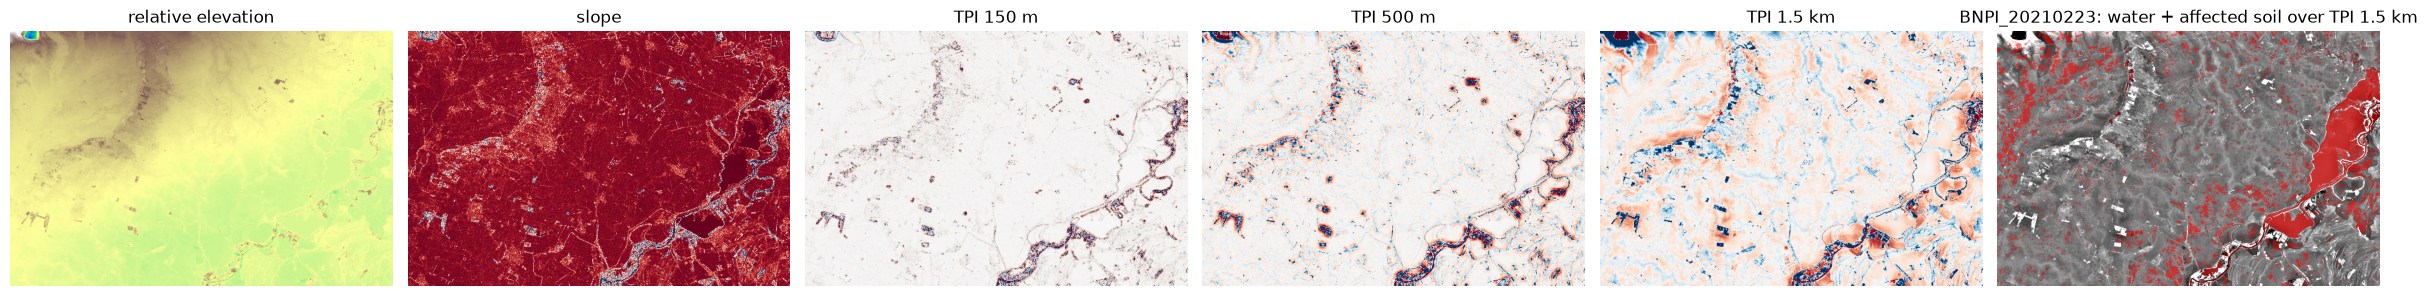

In [31]:
def cop_dem_tile(lat: int, lon: int):
    ns, ew = ("N" if lat >= 0 else "S"), ("E" if lon >= 0 else "W")
    name = f"Copernicus_DSM_COG_10_{ns}{abs(lat):02d}_00_{ew}{abs(lon):03d}_00_DEM"
    return name, f"https://copernicus-dem-30m.s3.amazonaws.com/{name}/{name}.tif"


def ensure_dem_tiles(sc: Scene):
    w, s, e, n = transform_bounds(sc.crs, "EPSG:4326", *sc.bounds, densify_pts=21)
    for lat in range(math.floor(s), math.floor(n) + 1):
        for lon in range(math.floor(w), math.floor(e) + 1):
            name, url = cop_dem_tile(lat, lon)
            path = DEM_RAW / f"{name}.tif"
            if path.exists():
                continue
            # Check if tile already exists anywhere in Kaggle input or outputs
            found_input = list(Path("/kaggle/input").glob(f"**/{name}.tif")) if Path("/kaggle/input").exists() else []
            if found_input:
                print(f"  found {name} in input directory, copying...")
                shutil.copy2(found_input[0], path)
                continue
            tmp = path.with_suffix(".part")
            try:
                print(f"  downloading {name} ...")
                req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
                with urllib.request.urlopen(req, timeout=60) as resp, open(tmp, "wb") as out:
                    shutil.copyfileobj(resp, out)
                tmp.rename(path)
            except Exception as ex:
                if tmp.exists():
                    tmp.unlink()
                print(f"  WARNING: could not download {name} ({ex}).")
                print("  Note: On Kaggle, ensure 'Internet' is toggled ON in the right sidebar (Settings -> Internet -> On).")


def dem_on_grid(sc: Scene) -> np.ndarray:
    dst = np.full((sc.H, sc.W), np.nan, dtype=np.float32)
    for tif in sorted(DEM_RAW.glob("*.tif")):
        with rasterio.open(tif) as src:
            l, b, r, t = transform_bounds(src.crs, sc.crs, *src.bounds, densify_pts=21)
            if r <= sc.bounds.left or l >= sc.bounds.right or t <= sc.bounds.bottom or b >= sc.bounds.top:
                continue
            tmp = np.full_like(dst, np.nan)
            reproject(source=rasterio.band(src, 1), destination=tmp,
                      src_transform=src.transform, src_crs=src.crs, src_nodata=src.nodata,
                      dst_transform=sc.transform, dst_crs=sc.crs, dst_nodata=np.nan,
                      resampling=Resampling.bilinear)
            fill = np.isnan(dst) & np.isfinite(tmp)
            dst[fill] = tmp[fill]
    return dst


def box_mean(a: np.ndarray, r: int) -> np.ndarray:
    """Mean over a (2r+1)x(2r+1) window, reflect-padded at the borders (integral image)."""
    k = 2 * r + 1
    p = np.pad(a.astype(np.float64), r, mode="reflect")
    I = np.zeros((p.shape[0] + 1, p.shape[1] + 1), dtype=np.float64)
    I[1:, 1:] = p.cumsum(0).cumsum(1)
    return ((I[k:, k:] - I[:-k, k:] - I[k:, :-k] + I[:-k, :-k]) / (k * k)).astype(np.float32)


def dem_features(dem: np.ndarray, pixel_m: float) -> np.ndarray:
    valid = np.isfinite(dem)
    if valid.mean() < 0.5:
        raise RuntimeError(f"DEM covers only {100 * valid.mean():.0f}% of the scene - check tiles in {DEM_RAW}")
    med = float(np.nanmedian(dem))
    dem = np.where(valid, dem, med).astype(np.float32)
    gy, gx = np.gradient(dem, pixel_m)
    slope = np.degrees(np.arctan(np.hypot(gx, gy)))
    radii = [max(1, int(round(m / pixel_m))) for m in (150, 500, 1500)]
    feats = [(dem - med) / 10.0, slope / 2.0] + [(dem - box_mean(dem, r)) / 2.0 for r in radii]
    return np.clip(np.stack(feats), -6.0, 6.0).astype(np.float16)


def grid_key(sc: Scene) -> str:
    return f"{sc.site}_{sc.H}x{sc.W}_{int(round(sc.transform.c))}_{int(round(sc.transform.f))}"


if USE_DEM:
    cache = {}
    for sc in all_train + all_test:
        key = grid_key(sc)
        if key not in cache:
            path = DEM_DIR / f"{key}.npy"
            if path.exists():
                cache[key] = np.load(path)
            else:
                t0 = time.time()
                print(f"Terrain features for {key}:")
                ensure_dem_tiles(sc)
                cache[key] = dem_features(dem_on_grid(sc), abs(sc.transform.a))
                np.save(path, cache[key])
                print(f"  done in {time.time() - t0:.0f}s -> {path}")
        sc.dem = cache[key]
    print(f"Terrain features ready for {len(cache)} site grid(s): {list(cache)}")

    first = all_train[0]
    names = ["relative elevation", "slope", "TPI 150 m", "TPI 500 m", "TPI 1.5 km"]
    fig, axes = plt.subplots(1, N_DEM + 1, figsize=(4 * (N_DEM + 1), 4))
    step = 8
    for k in range(N_DEM):
        im = axes[k].imshow(first.dem[k, ::step, ::step].astype(np.float32), cmap="terrain" if k == 0 else "RdBu",
                            vmin=None if k < 2 else -3, vmax=None if k < 2 else 3)
        axes[k].set_title(names[k]); axes[k].axis("off")
    soil = np.isin(first.gt[::step, ::step], [0, 1, 2, 3]).astype(np.float32)
    axes[-1].imshow(first.dem[4, ::step, ::step].astype(np.float32), cmap="gray", vmin=-3, vmax=3)
    axes[-1].imshow(np.ma.masked_where(soil == 0, soil), cmap="autumn", alpha=0.6)
    axes[-1].set_title(f"{first.name}: water + affected soil over TPI 1.5 km"); axes[-1].axis("off")
    plt.tight_layout(); plt.show()
else:
    print("USE_DEM = False - terrain channels are zero.")


## 3b. Patch sampling and dataset

The class-aware sampler is the same as in notebooks 10 and 11: 256-px windows on a 64-px grid with ±32 px jitter. Augmentation applies flips and 90° rotations identically to all inputs and the label, plus per-band gain noise on Sentinel-2.

In [32]:
def window_counts(mask: np.ndarray, size: int, rows: np.ndarray, cols: np.ndarray) -> np.ndarray:
    H, W = mask.shape
    integral = np.zeros((H + 1, W + 1), dtype=np.int32)
    integral[1:, 1:] = mask.cumsum(0, dtype=np.int32).cumsum(1, dtype=np.int32)
    r0, c0 = rows[:, None], cols[None, :]
    return (integral[r0 + size, c0 + size] - integral[r0, c0 + size]
            - integral[r0 + size, c0] + integral[r0, c0])


class PatchIndex:
    def __init__(self, scenes, patch: int, stride: int, min_valid: float = 0.10):
        sid, rr, cc, cnt = [], [], [], []
        for i, sc in enumerate(scenes):
            rows = np.arange(0, sc.H - patch + 1, stride)
            cols = np.arange(0, sc.W - patch + 1, stride)
            counts = np.stack([window_counts(sc.gt == k, patch, rows, cols)
                               for k in range(NUM_CLASSES)], axis=-1).reshape(-1, NUM_CLASSES)
            R, C = np.meshgrid(rows, cols, indexing="ij")
            keep = counts.sum(1) >= min_valid * patch * patch
            sid.append(np.full(int(keep.sum()), i, dtype=np.int32))
            rr.append(R.ravel()[keep]); cc.append(C.ravel()[keep]); cnt.append(counts[keep])
        self.scene_id = np.concatenate(sid)
        self.r = np.concatenate(rr).astype(np.int32)
        self.c = np.concatenate(cc).astype(np.int32)
        self.counts = np.concatenate(cnt).astype(np.int64)

    def __len__(self):
        return len(self.scene_id)

    def sample(self, n: int, rng: np.random.Generator) -> np.ndarray:
        picks = []
        for cls, share in CLASS_SHARE.items():
            w = np.sqrt(self.counts[:, cls].astype(np.float64))
            if w.sum() > 0:
                picks.append(rng.choice(len(self), size=int(round(n * share)), p=w / w.sum()))
        n_rest = n - sum(len(p) for p in picks)
        picks.append(rng.choice(len(self), size=n_rest))
        idx = np.concatenate(picks)
        rng.shuffle(idx)
        return idx


class PatchDataset(Dataset):
    def __init__(self, scenes, index, picks, patch: int, train: bool, jitter: int = 0, seed: int = 0):
        self.scenes, self.index, self.picks = scenes, index, picks
        self.patch, self.train, self.jitter, self.seed = patch, train, jitter, seed

    def __len__(self):
        return len(self.picks)

    def __getitem__(self, i):
        k = self.picks[i]
        sc = self.scenes[self.index.scene_id[k]]
        r, c = int(self.index.r[k]), int(self.index.c[k])
        P = self.patch
        rng = np.random.default_rng((self.seed, int(i))) if self.train else None
        if self.train and self.jitter:
            r = int(np.clip(r + rng.integers(-self.jitter, self.jitter + 1), 0, sc.H - P))
            c = int(np.clip(c + rng.integers(-self.jitter, self.jitter + 1), 0, sc.W - P))
        s2_raw, s1_raw, dem = sc.read(r, c, P, P)
        if self.train and GAIN_JITTER > 0:
            gains = rng.uniform(1 - GAIN_JITTER, 1 + GAIN_JITTER, size=(s2_raw.shape[0], 1, 1)).astype(np.float32)
            s2_raw = s2_raw.astype(np.float32) * gains
        s2, s1, aux = make_inputs(s2_raw, s1_raw, dem)
        y = sc.gt[r:r + P, c:c + P]
        if self.train:
            if rng.random() < 0.5:
                s2, s1, aux, y = s2[..., ::-1], s1[..., ::-1], aux[..., ::-1], y[:, ::-1]
            if rng.random() < 0.5:
                s2, s1, aux, y = s2[..., ::-1, :], s1[..., ::-1, :], aux[..., ::-1, :], y[::-1, :]
            k90 = int(rng.integers(0, 4))
            if k90:
                s2, s1, aux = (np.rot90(a, k90, axes=(-2, -1)) for a in (s2, s1, aux))
                y = np.rot90(y, k90, axes=(0, 1))
        return {
            "s2": torch.from_numpy(np.ascontiguousarray(s2)),
            "s1": torch.from_numpy(np.ascontiguousarray(s1)),
            "aux": torch.from_numpy(np.ascontiguousarray(aux)),
            "y": torch.from_numpy(np.ascontiguousarray(y).astype(np.int64)),
        }


def make_loader(dataset):
    return DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS,
                      pin_memory=device.type == "cuda", drop_last=False)


def to_dev(batch):
    return {k: v.to(device, non_blocking=True) for k, v in batch.items()}


t0 = time.time()
train_index = PatchIndex(train_scenes, PATCH, GRID_STRIDE)
val_index   = PatchIndex(val_scenes, PATCH, PATCH)
print(f"Indexes built in {time.time() - t0:.0f}s | train locations {len(train_index):,} | val locations {len(val_index):,}")

train_pixels = np.zeros(NUM_CLASSES, dtype=np.int64)
for sc in train_scenes:
    train_pixels += np.bincount(sc.gt.ravel(), minlength=256)[:NUM_CLASSES]
freq = train_pixels / train_pixels.sum()
class_weights = (1.0 / freq) ** 0.5
class_weights = torch.tensor(class_weights / class_weights.mean(), dtype=torch.float32)
coarse_pixels = np.array([train_pixels[0], train_pixels[1:4].sum(), train_pixels[4], train_pixels[5]], dtype=np.float64)
coarse_weights = (coarse_pixels.sum() / coarse_pixels) ** 0.5
coarse_weights = torch.tensor(coarse_weights / coarse_weights.mean(), dtype=torch.float32)
n_ser, n_mod, n_sli = train_pixels[1], train_pixels[2], train_pixels[3]
ORD_POS_WEIGHT = torch.tensor([np.clip(n_sli / max(n_mod + n_ser, 1), 0.5, 4.0),
                               np.clip(n_mod / max(n_ser, 1), 0.5, 4.0)], dtype=torch.float32)

print("\nClass frequency in training scenes and loss weights:")
for k in range(NUM_CLASSES):
    print(f"  {CLASS_NAMES[k]:<34s} {100 * freq[k]:6.2f} %   weight {class_weights[k]:.2f}")

val_picks = val_index.sample(VAL_PATCHES, np.random.default_rng(SEED + 12345))
val_loader = make_loader(PatchDataset(val_scenes, val_index, val_picks, PATCH, train=False))

Indexes built in 48s | train locations 52,752 | val locations 594

Class frequency in training scenes and loss weights:
  Open surface water (raw 2)           3.66 %   weight 0.58
  Soil seriously affected (raw 3)      0.32 %   weight 1.96
  Soil moderately affected (raw 4)     0.41 %   weight 1.73
  Soil slightly affected (raw 5)       2.22 %   weight 0.75
  Vegetation affected (raw 6)          1.65 %   weight 0.87
  Not affected (raw 7)                91.73 %   weight 0.12


## 4. Model: two SSL4EO-S12 ViTs + terrain CNN + UPerNet

- **`load_ssl4eo_vit`** builds a timm ViT through `torchgeo` with SSL4EO-S12 **MAE** weights (`SENTINEL2_ALL_MAE` for optics, `SENTINEL1_GRD_MAE` for radar). The optical weights expect 13 Sentinel-2 bands; this dataset has 11 (no B9/B10), so the patch-embedding convolution is **adapted** by dropping the B9 and B10 filter slices and rescaling by 13/11. The radar weights expect 2 channels.
- **`ViTEncoder`** runs patch embedding, position embedding and the transformer blocks, and returns the token maps of four blocks (¼, ½, ¾ and the full depth). The final norm is applied to the last one.
- Each tap becomes a `(B, 128, 14, 14)` map and a **simple feature pyramid** (×4 up, ×2 up, same, ×½) produces the four scales UPerNet needs. S2, S1 and the terrain CNN are **fused at every scale** with a channel gate.
- A **CNN detail branch** at full and half resolution on all 28 input channels restores the fine boundaries that a 16-px-patch ViT cannot represent.
- Heads and outputs are identical to notebooks 12 and 13: main (6), coarse (4), ordinal (2), plus an auxiliary head at ¼ resolution.

In [33]:
S2_KEEP = [0, 1, 2, 3, 4, 5, 6, 7, 8, 11, 12]     # SSL4EO 13-band order minus B9 (idx 9) and B10 (idx 10)

VIT_SPECS = {"small16": dict(fn="vit_small_patch16_224", weights="ViTSmall16_Weights", dim=384, depth=12),
             "base16":  dict(fn="vit_base_patch16_224",  weights="ViTBase16_Weights",  dim=768, depth=12)}
SPEC = VIT_SPECS[ENCODER]


def load_ssl4eo_vit(kind: str) -> nn.Module:
    """kind = 's2' or 's1' -> timm ViT with SSL4EO-S12 MAE weights (if PRETRAINED)."""
    try:
        import torchgeo.models as tgm
    except ImportError as ex:
        raise ImportError('This notebook needs torchgeo: pip install -U "torchgeo>=0.7"') from ex
    if not hasattr(tgm, SPEC["fn"]) or not hasattr(tgm, SPEC["weights"]):
        raise AttributeError(f"torchgeo {getattr(__import__('torchgeo'), '__version__', '?')} lacks "
                             f"{SPEC['fn']} / {SPEC['weights']} - upgrade: pip install -U 'torchgeo>=0.7'")
    member = "SENTINEL2_ALL_MAE" if kind == "s2" else "SENTINEL1_GRD_MAE"
    builder, enum = getattr(tgm, SPEC["fn"]), getattr(tgm, SPEC["weights"])
    if PRETRAINED:
        if not hasattr(enum, member):
            raise AttributeError(f"{SPEC['weights']}.{member} not found; available: {[w.name for w in enum]}")
        vit = builder(weights=getattr(enum, member))
    else:
        vit = builder(weights=None, in_chans=13 if kind == "s2" else 2)
    if kind == "s2":
        old = vit.patch_embed.proj
        assert old.in_channels == 13, f"expected a 13-band patch embedding, got {old.in_channels}"
        new = nn.Conv2d(11, old.out_channels, old.kernel_size, old.stride, old.padding, bias=old.bias is not None)
        with torch.no_grad():
            new.weight.copy_(old.weight[:, S2_KEEP] * (13.0 / 11.0))
            if old.bias is not None:
                new.bias.copy_(old.bias)
        vit.patch_embed.proj = new
    return vit


class ViTEncoder(nn.Module):
    """Runs a timm ViT manually and returns the token sequences (B, 1 + N, D) after the tapped blocks."""
    def __init__(self, vit: nn.Module, taps):
        super().__init__()
        self.vit, self.taps = vit, set(taps)

    def forward(self, x):
        v = self.vit
        x = v.patch_embed(x)
        if x.ndim == 4:                                   # (B, H, W, D) in some timm versions
            x = x.flatten(1, 2)
        if hasattr(v, "_pos_embed"):
            x = v._pos_embed(x)
        else:
            x = torch.cat([v.cls_token.expand(x.shape[0], -1, -1), x], dim=1) + v.pos_embed
        if hasattr(v, "norm_pre"):
            x = v.norm_pre(x)
        feats, last = [], len(v.blocks) - 1
        for i, blk in enumerate(v.blocks):
            x = blk(x)
            if i in self.taps:
                feats.append(v.norm(x) if i == last else x)
        return feats


def tokens_to_map(tok: torch.Tensor, g: int) -> torch.Tensor:
    B, L, D = tok.shape
    assert L == 1 + g * g, f"unexpected token count {L} (expected {1 + g * g})"
    return tok[:, 1:].transpose(1, 2).reshape(B, D, g, g)


def cna(cin: int, cout: int, k: int = 3, s: int = 1) -> nn.Sequential:
    return nn.Sequential(nn.Conv2d(cin, cout, k, s, k // 2, bias=False), nn.GroupNorm(8, cout), nn.GELU())


class AuxEncoder(nn.Module):
    def __init__(self, cin: int, dims=(64, 128, 192, 256)):
        super().__init__()
        self.stem = nn.Sequential(cna(cin, 32), cna(32, dims[0], s=2), cna(dims[0], dims[0], s=2), cna(dims[0], dims[0]))
        self.stages = nn.ModuleList([nn.Sequential(cna(dims[i - 1], dims[i], s=2), cna(dims[i], dims[i]))
                                     for i in range(1, len(dims))])

    def forward(self, x):
        y = self.stem(x)
        feats = [y]
        for st in self.stages:
            y = st(y)
            feats.append(y)
        return feats


class FuseBlock(nn.Module):
    def __init__(self, cin: int, cout: int = 256):
        super().__init__()
        self.proj = nn.Sequential(nn.Conv2d(cin, cout, 1, bias=False), nn.GroupNorm(8, cout), nn.GELU(), cna(cout, cout))
        self.gate = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Conv2d(cout, cout // 8, 1), nn.GELU(),
                                  nn.Conv2d(cout // 8, cout, 1), nn.Sigmoid())

    def forward(self, *xs):
        y = self.proj(torch.cat(xs, dim=1))
        return y * self.gate(y)


class UPerHead(nn.Module):
    def __init__(self, ch: int = 256, n_levels: int = 4, bins=(1, 2, 3, 6)):
        super().__init__()
        self.ppm = nn.ModuleList([nn.Sequential(nn.AdaptiveAvgPool2d(b), nn.Conv2d(ch, 64, 1, bias=False),
                                                nn.GroupNorm(8, 64), nn.GELU()) for b in bins])
        self.ppm_out = cna(ch + 64 * len(bins), ch)
        self.smooth = nn.ModuleList([cna(ch, ch) for _ in range(n_levels - 1)])
        self.fuse = cna(ch * n_levels, ch)

    def forward(self, feats):
        top = feats[-1]
        pooled = [F.interpolate(m(top), size=top.shape[-2:], mode="bilinear", align_corners=False) for m in self.ppm]
        p = [None] * len(feats)
        p[-1] = self.ppm_out(torch.cat([top] + pooled, dim=1))
        for i in range(len(feats) - 2, -1, -1):
            p[i] = self.smooth[i](feats[i] + F.interpolate(p[i + 1], size=feats[i].shape[-2:],
                                                           mode="bilinear", align_corners=False))
        size = p[0].shape[-2:]
        return self.fuse(torch.cat([p[0]] + [F.interpolate(x, size=size, mode="bilinear", align_corners=False)
                                             for x in p[1:]], dim=1))



def make_pyramid(c: int) -> nn.ModuleList:
    up = lambda: nn.Sequential(nn.ConvTranspose2d(c, c, 2, stride=2), nn.GroupNorm(8, c), nn.GELU())
    return nn.ModuleList([nn.Sequential(up(), up()),               # 1/16 -> 1/4
                          up(),                                    # 1/16 -> 1/8
                          nn.Identity(),                           # 1/16
                          nn.Sequential(nn.Conv2d(c, c, 3, stride=2, padding=1, bias=False),
                                        nn.GroupNorm(8, c), nn.GELU())])   # 1/32


class ViTUPerNet(nn.Module):
    AUX_DIMS = (64, 128, 192, 256)

    def __init__(self, num_classes: int = NUM_CLASSES, ch: int = 256, pch: int = 128):
        super().__init__()
        depth, dim = SPEC["depth"], SPEC["dim"]
        taps = [depth // 4 - 1, depth // 2 - 1, 3 * depth // 4 - 1, depth - 1]
        self.g = PATCH // 16
        self.enc_s2 = ViTEncoder(load_ssl4eo_vit("s2"), taps)
        self.enc_s1 = ViTEncoder(load_ssl4eo_vit("s1"), taps)
        mk = lambda: nn.ModuleList([nn.Sequential(nn.Conv2d(dim, pch, 1, bias=False), nn.GroupNorm(8, pch), nn.GELU())
                                    for _ in range(4)])
        self.proj2, self.proj1 = mk(), mk()
        self.pyr2, self.pyr1 = make_pyramid(pch), make_pyramid(pch)
        self.enc_aux = AuxEncoder(AUX_CH, self.AUX_DIMS)
        self.fuse = nn.ModuleList([FuseBlock(2 * pch + ac, ch) for ac in self.AUX_DIMS])
        self.uper = UPerHead(ch, 4)
        self.aux_head = nn.Conv2d(ch, num_classes, 1)              # deep supervision @ 1/4
        # CNN detail branch on all inputs (full and half resolution)
        self.c1 = nn.Sequential(cna(FULL_CH, 32), cna(32, 32))
        self.c2 = nn.Sequential(cna(32, 64, s=2), cna(64, 64))
        self.full_spec = nn.Sequential(nn.Conv2d(FULL_CH, 64, 1, bias=False), nn.GroupNorm(8, 64), nn.GELU(),
                                       nn.Conv2d(64, 64, 1, bias=False), nn.GroupNorm(8, 64), nn.GELU())
        self.up_half = nn.Sequential(cna(ch + 64, 128), cna(128, 128))
        self.up_full = nn.Sequential(cna(128 + 64 + 32, 64), cna(64, 64))
        self.drop = nn.Dropout2d(0.1)
        self.head = nn.Conv2d(64, num_classes, 1)
        self.coarse_head = nn.Conv2d(64, 4, 1)
        self.ordinal_head = nn.Conv2d(64, 2, 1)
        self.register_buffer("s2_mean", torch.tensor(S2_MEAN).view(1, -1, 1, 1))
        self.register_buffer("s2_std", torch.tensor(S2_STD).view(1, -1, 1, 1))

    def forward(self, b):
        s2, s1, aux = b["s2"], b["s1"], b["aux"]
        f2, f1, fa = self.enc_s2(s2), self.enc_s1(s1), self.enc_aux(aux)
        fused = []
        for i in range(4):
            m2 = self.pyr2[i](self.proj2[i](tokens_to_map(f2[i], self.g)))
            m1 = self.pyr1[i](self.proj1[i](tokens_to_map(f1[i], self.g)))
            fused.append(self.fuse[i](m2, m1, fa[i]))
        dec = self.uper(fused)                                      # 256 ch @ 1/4
        full_in = torch.cat([((s2 - self.s2_mean) / self.s2_std) * aux[:, 7:8], s1, aux], dim=1)
        c1 = self.c1(full_in)
        c2 = self.c2(c1)
        x = F.interpolate(dec, scale_factor=2, mode="bilinear", align_corners=False)
        x = self.up_half(torch.cat([x, c2], dim=1))
        x = F.interpolate(x, scale_factor=2, mode="bilinear", align_corners=False)
        x = self.up_full(torch.cat([x, self.full_spec(full_in), c1], dim=1))
        x = self.drop(x)
        return {"logits": self.head(x), "coarse": self.coarse_head(x), "ordinal": self.ordinal_head(x),
                "aux": self.aux_head(dec)}


def compose_probs(out):
    """Flat softmax and hierarchical (coarse x ordinal severity) class probabilities, both (B,6,H,W)."""
    p_main = F.softmax(out["logits"].float(), dim=1)
    pc = F.softmax(out["coarse"].float(), dim=1)
    z = out["ordinal"].float()
    ge1 = torch.sigmoid(z[:, 0])
    ge2 = ge1 * torch.sigmoid(z[:, 1])
    p_h = torch.stack([pc[:, 0], pc[:, 1] * ge2, pc[:, 1] * (ge1 - ge2), pc[:, 1] * (1 - ge1),
                       pc[:, 2], pc[:, 3]], dim=1)
    return p_main, p_h


model = ViTUPerNet().to(device)

# --- which parts train: everything outside the ViTs, plus the last K blocks + final norm of each ViT ---
ENCODERS = (model.enc_s2, model.enc_s1)
ENC_PREFIXES = ("enc_s2.", "enc_s1.")
tunable = []
for enc in ENCODERS:
    for blk in list(enc.vit.blocks)[-UNFREEZE_LAST_BLOCKS:]:
        tunable += list(blk.parameters())
    tunable += list(enc.vit.norm.parameters())
tunable_ids = {id(p) for p in tunable}
for enc in ENCODERS:
    for p in enc.parameters():
        p.requires_grad_(False)                   # fully frozen until the unfreeze epoch
head_params = [p for n, p in model.named_parameters() if not n.startswith(ENC_PREFIXES)]
bb_params = [p for enc in ENCODERS for p in enc.parameters() if id(p) in tunable_ids]
bb_names = {n for n, p in model.named_parameters() if id(p) in tunable_ids}
SAVE_KEYS = {k for k in model.state_dict() if not k.startswith(ENC_PREFIXES) or k in bb_names}

n_total = sum(p.numel() for p in model.parameters())
n_enc = sum(p.numel() for enc in ENCODERS for p in enc.parameters())
print(f"ViTUPerNet ({ENCODER}): {n_total / 1e6:.1f}M params | two ViT encoders {n_enc / 1e6:.1f}M "
      f"(tunable last blocks: {sum(p.numel() for p in bb_params) / 1e6:.1f}M) | "
      f"new layers {sum(p.numel() for p in head_params) / 1e6:.1f}M | pretrained={PRETRAINED}")

# --- smoke test: shapes and memory of one phase-2 training step ---------------------------------
for p in bb_params:
    p.requires_grad_(True)
_b = {"s2": torch.rand(2, 11, PATCH, PATCH, device=device) * 0.3,
      "s1": torch.randn(2, 2, PATCH, PATCH, device=device),
      "aux": torch.randn(2, AUX_CH, PATCH, PATCH, device=device)}
if device.type == "cuda":
    torch.cuda.reset_peak_memory_stats()
model.train()
with autocast():
    _out = model(_b)
    _loss = sum(v.float().mean() for v in _out.values())
_loss.backward()
model.zero_grad(set_to_none=True)
print("Output shapes:", {k: tuple(v.shape) for k, v in _out.items()})
if device.type == "cuda":
    peak = torch.cuda.max_memory_allocated() / 2**30
    print(f"Peak GPU memory, batch of 2 @ {PATCH}px (fwd+bwd, last blocks unfrozen): {peak:.2f} GB "
          f"(batch {BATCH_SIZE} is roughly {peak + (BATCH_SIZE - 2) * 0.3:.1f} GB)")
for p in bb_params:
    p.requires_grad_(False)
del _b, _out, _loss
if device.type == "cuda":
    torch.cuda.empty_cache()

Downloading: "https://huggingface.co/wangyi111/SSL4EO-S12/resolve/75c72195d35201dc1fb210818993518c25da566b/B13_vitb16_mae_ep99_enc.pth" to C:\Users\HP/.cache\torch\hub\checkpoints\B13_vitb16_mae_ep99_enc.pth
100%|██████████| 335M/335M [07:16<00:00, 805kB/s]  
Downloading: "https://huggingface.co/wangyi111/SSL4EO-S12/resolve/75c72195d35201dc1fb210818993518c25da566b/B2_vitb16_mae_ep99_enc.pth" to C:\Users\HP/.cache\torch\hub\checkpoints\B2_vitb16_mae_ep99_enc.pth
100%|██████████| 327M/327M [04:57<00:00, 1.15MB/s]  


ViTUPerNet (base16): 186.9M params | two ViT encoders 174.5M (tunable last blocks: 56.7M) | new layers 12.4M | pretrained=True
Output shapes: {'logits': (2, 6, 224, 224), 'coarse': (2, 4, 224, 224), 'ordinal': (2, 2, 224, 224), 'aux': (2, 6, 56, 56)}
Peak GPU memory, batch of 2 @ 224px (fwd+bwd, last blocks unfrozen): 3.59 GB (batch 4 is roughly 4.2 GB)


## 5. Losses and metrics

The same structured loss as notebooks 11 to 13: `main + 0.3·aux + 0.4·coarse + 0.4·ordinal`, with ordinal label smoothing between neighbouring soil grades. Metrics are identical to notebooks 10 to 13.

In [34]:
COARSE_OF = torch.tensor([0, 1, 1, 1, 2, 3])
RANK_OF   = torch.tensor([0, 2, 1, 0, 0, 0])


def ordinal_soft_targets(eps: float) -> torch.Tensor:
    S = torch.eye(NUM_CLASSES)
    S[1] = 0; S[1, 1] = 1 - eps; S[1, 2] = eps
    S[2] = 0; S[2, 2] = 1 - eps; S[2, 1] = eps / 2; S[2, 3] = eps / 2
    S[3] = 0; S[3, 3] = 1 - eps; S[3, 2] = eps
    return S


class StructuredLoss(nn.Module):
    def __init__(self, class_w, coarse_w, ord_pos_w, eps=ORDINAL_SMOOTH,
                 dice_w=0.5, aux_w=0.3, coarse_wt=0.4, ord_wt=0.4):
        super().__init__()
        self.register_buffer("w", class_w)
        self.register_buffer("cw", coarse_w)
        self.register_buffer("opw", ord_pos_w)
        self.register_buffer("S", ordinal_soft_targets(eps))
        self.register_buffer("coarse_of", COARSE_OF)
        self.register_buffer("rank_of", RANK_OF)
        self.dice_w, self.aux_w, self.coarse_wt, self.ord_wt = dice_w, aux_w, coarse_wt, ord_wt

    def soft_ce(self, logits, yt, valid):
        if logits.shape[-2:] != yt.shape[-2:]:
            logits = F.interpolate(logits.float(), size=yt.shape[-2:], mode="bilinear", align_corners=False)
        logp = F.log_softmax(logits.float(), dim=1)
        tgt = self.S[yt].permute(0, 3, 1, 2)
        wpx = self.w[yt] * valid
        return (-(tgt * logp).sum(1) * wpx).sum() / wpx.sum().clamp_min(1e-6)

    def dice(self, logits, yt, valid):
        onehot = F.one_hot(yt, NUM_CLASSES).permute(0, 3, 1, 2).float() * valid[:, None]
        probs = F.softmax(logits.float(), dim=1) * valid[:, None]
        inter = (probs * onehot).sum((0, 2, 3))
        denom = (probs + onehot).sum((0, 2, 3))
        present = onehot.sum((0, 2, 3)) > 0
        return (1.0 - (2.0 * inter + 1.0) / (denom + 1.0))[present].mean()

    def forward(self, out, y):
        valid = y != IGNORE
        if not valid.any():
            return out["logits"].float().sum() * 0.0, {}
        yt = torch.where(valid, y, torch.zeros_like(y))
        vf = valid.float()
        main = self.soft_ce(out["logits"], yt, vf) + self.dice_w * self.dice(out["logits"], yt, vf)
        aux = self.soft_ce(out["aux"], yt, vf)
        yc = torch.where(valid, self.coarse_of[yt], torch.full_like(y, IGNORE))
        coarse = F.cross_entropy(out["coarse"].float(), yc, weight=self.cw, ignore_index=IGNORE)
        z = out["ordinal"].float()
        rank = self.rank_of[yt]
        soil = valid & (yt >= 1) & (yt <= 3)
        ordl = z.sum() * 0.0
        if soil.any():
            ordl = ordl + F.binary_cross_entropy_with_logits(z[:, 0][soil], (rank[soil] >= 1).float(),
                                                             pos_weight=self.opw[0])
            m2 = soil & (rank >= 1)
            if m2.any():
                ordl = ordl + F.binary_cross_entropy_with_logits(z[:, 1][m2], (rank[m2] >= 2).float(),
                                                                 pos_weight=self.opw[1])
        total = main + self.aux_w * aux + self.coarse_wt * coarse + self.ord_wt * ordl
        return total, {"main": main.item(), "aux": aux.item(), "coarse": coarse.item(), "ordinal": ordl.item()}


def confusion(y_true: np.ndarray, y_pred: np.ndarray) -> np.ndarray:
    keep = (y_true != IGNORE) & (y_pred != IGNORE)
    return np.bincount(NUM_CLASSES * y_true[keep].astype(np.int64) + y_pred[keep].astype(np.int64),
                       minlength=NUM_CLASSES ** 2).reshape(NUM_CLASSES, NUM_CLASSES)


def prf(cm: np.ndarray):
    tp = np.diag(cm).astype(np.float64)
    pr = tp / np.maximum(cm.sum(0), 1)
    rc = tp / np.maximum(cm.sum(1), 1)
    f1 = 2 * pr * rc / np.maximum(pr + rc, 1e-12)
    return pr, rc, f1


def macro_f1(cm: np.ndarray, classes=range(NUM_CLASSES)) -> float:
    f1 = prf(cm)[2]
    present = [k for k in classes if cm[k].sum() > 0]
    return float(np.mean([f1[k] for k in present])) if present else 0.0


def report(cm: np.ndarray, title: str) -> dict:
    pr, rc, f1 = prf(cm)
    support = cm.sum(1)
    line = "=" * 86
    print(f"\n{line}\n{title}\n{line}")
    print(f"{'Cls':<4}{'Name':<36}{'Pr (%)':>9}{'Rc (%)':>9}{'F1 (%)':>9}{'Pixels':>16}")
    print("-" * 86)
    for k in range(NUM_CLASSES):
        print(f"{k:<4}{CLASS_NAMES[k]:<36}{100 * pr[k]:>9.2f}{100 * rc[k]:>9.2f}{100 * f1[k]:>9.2f}{support[k]:>16,}")
    print("-" * 86)
    w5 = support[:5] / max(support[:5].sum(), 1)
    out = {
        "precision": pr.tolist(), "recall": rc.tolist(), "f1": f1.tolist(),
        "macro_f1_all": macro_f1(cm), "macro_f1_water": macro_f1(cm, range(5)),
        "weighted_water": [float((pr[:5] * w5).sum()), float((rc[:5] * w5).sum()), float((f1[:5] * w5).sum())],
    }
    wp, wr, wf = out["weighted_water"]
    print(f"{'':4}{'MACRO-F1, all 6 classes':<36}{'':>18}{100 * out['macro_f1_all']:>9.2f}")
    print(f"{'':4}{'MACRO-F1, water-related (raw 2-6)':<36}{'':>18}{100 * out['macro_f1_water']:>9.2f}")
    print(f"{'':4}{'Pixel-weighted, raw 2-6 (Table 1)':<36}{100 * wp:>9.2f}{100 * wr:>9.2f}{100 * wf:>9.2f}")
    print(line)
    return out


criterion = StructuredLoss(class_weights, coarse_weights, ORD_POS_WEIGHT).to(device)


@torch.no_grad()
def evaluate_patches(net, loader, drop_dem=False, drop_s1=False, alpha=0.5):
    net.eval()
    cm_main = np.zeros((NUM_CLASSES, NUM_CLASSES), dtype=np.int64)
    cm_blend = np.zeros_like(cm_main)
    total, n = 0.0, 0
    for b in loader:
        b = to_dev(b)
        if drop_dem:
            b["aux"][:, AUX_CH - N_DEM:] = 0
        if drop_s1:
            b["s1"] = torch.zeros_like(b["s1"])
            b["aux"][:, 8:10] = 0                 # VV/VH ratio + S1 valid flag
        with autocast():
            out = net(b)
        loss, _ = criterion(out, b["y"])
        total += loss.item(); n += 1
        p_main, p_h = compose_probs(out)
        y = b["y"].cpu().numpy()
        cm_main += confusion(y, p_main.argmax(1).cpu().numpy())
        cm_blend += confusion(y, ((1 - alpha) * p_main + alpha * p_h).argmax(1).cpu().numpy())
    return total / max(n, 1), cm_main, cm_blend

## 6. Fine-tuning

- **Epochs 1…`FREEZE_EPOCHS`:** both ViTs frozen; fusion, decoder, CNN branches and heads train at `HEAD_LR`.
- **Afterwards:** the last `UNFREEZE_LAST_BLOCKS` blocks and the final norm of each ViT also train, at `BACKBONE_LR`.
- One-cycle learning rate per group, AdamW, gradient clipping at 1.0, mixed precision, gradient accumulation.
- **EMA** of the trainable weights; the EMA weights are validated each epoch and the best (flat or blended macro-F1 on the two held-out training scenes) is saved. Checkpoints store only the trainable part.

In [35]:
class EMA:
    """Exponential moving average over the trainable part of the model (frozen weights never change)."""
    def __init__(self, net, keys):
        self.keys = sorted(keys)
        sd = net.state_dict()
        self.shadow = {k: sd[k].detach().clone() for k in self.keys}

    @torch.no_grad()
    def update(self, net, step: int):
        decay = min(EMA_DECAY, (1 + step) / (10 + step))
        sd = net.state_dict()
        for k in self.keys:
            if self.shadow[k].dtype.is_floating_point:
                self.shadow[k].mul_(decay).add_(sd[k].detach(), alpha=1 - decay)
            else:
                self.shadow[k].copy_(sd[k])

    @contextlib.contextmanager
    def applied(self, net):
        sd = net.state_dict()
        backup = {k: sd[k].detach().clone() for k in self.keys}
        net.load_state_dict(self.shadow, strict=False)
        try:
            yield
        finally:
            net.load_state_dict(backup, strict=False)


def state_subset(net):
    sd = net.state_dict()
    return {k: v.detach().cpu() for k, v in sd.items() if k in SAVE_KEYS}


def load_subset(net, state):
    res = net.load_state_dict(state, strict=False)
    bad = [k for k in res.missing_keys if k in SAVE_KEYS] + list(res.unexpected_keys)
    assert not bad, f"checkpoint does not match the model: {bad[:5]}"


optimizer = torch.optim.AdamW([{"params": head_params, "lr": HEAD_LR},
                               {"params": bb_params, "lr": BACKBONE_LR}], weight_decay=WEIGHT_DECAY)
loader_steps = math.ceil(SAMPLES_PER_EPOCH / BATCH_SIZE)
opt_steps_per_epoch = math.ceil(loader_steps / ACCUM_STEPS)
scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=[HEAD_LR, BACKBONE_LR],
                                                total_steps=EPOCHS * opt_steps_per_epoch, pct_start=WARMUP_FRAC)
scaler = make_scaler()
ema = EMA(model, SAVE_KEYS)

run_cfg = {"epochs": EPOCHS, "freeze": FREEZE_EPOCHS, "unfreeze": UNFREEZE_LAST_BLOCKS, "samples": SAMPLES_PER_EPOCH,
           "batch": BATCH_SIZE, "accum": ACCUM_STEPS, "patch": PATCH, "head_lr": HEAD_LR, "bb_lr": BACKBONE_LR,
           "val_scenes": VAL_SCENES, "backbone": BACKBONE, "pretrained": PRETRAINED, "dem": USE_DEM}
history = {"train_loss": [], "val_loss": [], "val_macro_f1": [], "val_macro_f1_blend": [], "val_f1": []}
start_epoch, best_score, global_step = 1, -1.0, 0

if RESUME and LAST_PATH.exists():
    st = torch.load(LAST_PATH, map_location=device, weights_only=False)
    if st.get("run_cfg") == run_cfg:
        load_subset(model, st["model"])
        ema.shadow = {k: v.to(device) for k, v in st["ema"].items()}
        optimizer.load_state_dict(st["optimizer"]); scheduler.load_state_dict(st["scheduler"])
        scaler.load_state_dict(st["scaler"])
        history, best_score, global_step = st["history"], st["best_score"], st["global_step"]
        start_epoch = st["epoch"] + 1
        print(f"Resuming from epoch {start_epoch} (best val macro-F1 so far {100 * best_score:.2f})")
    else:
        print("Found a checkpoint from a different configuration - starting fresh.")

print(f"Fine-tuning: epochs {start_epoch}..{EPOCHS} (both ViTs fully frozen for epochs <= {FREEZE_EPOCHS}) | "
      f"{loader_steps} batches/epoch, optimizer step every {ACCUM_STEPS} | patch {PATCH}")

for epoch in range(start_epoch, EPOCHS + 1):
    t0 = time.time()
    frozen = epoch <= FREEZE_EPOCHS
    for p in bb_params:
        p.requires_grad_(not frozen)
    picks = train_index.sample(SAMPLES_PER_EPOCH, np.random.default_rng(SEED + 1000 * epoch))
    loader = make_loader(PatchDataset(train_scenes, train_index, picks, PATCH, train=True,
                                      jitter=GRID_STRIDE // 2, seed=SEED + epoch))
    model.train()
    running, parts_sum, n_steps = 0.0, {}, len(loader)
    optimizer.zero_grad(set_to_none=True)
    for step, b in enumerate(loader, 1):
        b = to_dev(b)
        with autocast():
            out = model(b)
        loss, parts = criterion(out, b["y"])
        scaler.scale(loss / ACCUM_STEPS).backward()
        if step % ACCUM_STEPS == 0 or step == n_steps:
            scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_([p for p in model.parameters() if p.requires_grad], 1.0)
            scaler.step(optimizer); scaler.update(); scheduler.step()
            optimizer.zero_grad(set_to_none=True)
            global_step += 1
            ema.update(model, global_step)
        running += loss.item()
        for k, v in parts.items():
            parts_sum[k] = parts_sum.get(k, 0.0) + v
        if step % 25 == 0:
            print(f"  epoch {epoch} step {step}/{n_steps} loss {running / step:.4f} "
                  f"({(time.time() - t0) / step:.2f}s/step)", end="\r")

    train_loss = running / n_steps
    with ema.applied(model):
        val_loss, cm_main, cm_blend = evaluate_patches(model, val_loader)
    s_main, s_blend = macro_f1(cm_main), macro_f1(cm_blend)
    score = max(s_main, s_blend)
    f1 = prf(cm_blend if s_blend >= s_main else cm_main)[2]
    history["train_loss"].append(train_loss); history["val_loss"].append(val_loss)
    history["val_macro_f1"].append(s_main); history["val_macro_f1_blend"].append(s_blend)
    history["val_f1"].append([float(v) for v in f1])

    improved = score > best_score
    if improved:
        best_score = score
        torch.save({"model": {k: v.cpu() for k, v in ema.shadow.items()}, "epoch": epoch, "val_macro_f1": score}, BEST_PATH)
    torch.save({"model": state_subset(model), "ema": {k: v.cpu() for k, v in ema.shadow.items()},
                "optimizer": optimizer.state_dict(), "scheduler": scheduler.state_dict(),
                "scaler": scaler.state_dict(), "epoch": epoch, "history": history, "best_score": best_score,
                "global_step": global_step, "run_cfg": run_cfg}, LAST_PATH)
    parts_txt = " ".join(f"{k} {v / n_steps:.3f}" for k, v in parts_sum.items())
    print(f"Epoch {epoch:2d}/{EPOCHS}{' [ViTs frozen]' if frozen else ''} | train {train_loss:.4f} ({parts_txt}) | "
          f"val {val_loss:.4f} | macro-F1 flat {100 * s_main:5.2f} blend {100 * s_blend:5.2f} | per-class "
          + " ".join(f"{100 * v:4.1f}" for v in f1)
          + f" | {(time.time() - t0) / 60:.1f} min{' *' if improved else ''}")

print(f"\nTraining complete. Best val macro-F1 (EMA): {100 * best_score:.2f} -> {BEST_PATH}")

Fine-tuning: epochs 1..2 (both ViTs fully frozen for epochs <= 1) | 4 batches/epoch, optimizer step every 2 | patch 224
Epoch  1/2 [ViTs frozen] | train 4.0172 (main 2.135 aux 1.995 coarse 1.372 ordinal 1.837) | val 3.6946 | macro-F1 flat 15.36 blend 15.07 | per-class  0.0  0.0  0.0  1.1  0.9 90.1 | 0.2 min *
Epoch  2/2 | train 3.7767 (main 1.978 aux 1.789 coarse 1.240 ordinal 1.914) | val 3.6789 | macro-F1 flat 23.06 blend 15.09 | per-class  0.2  0.0  0.0 45.8  1.7 90.7 | 0.2 min *

Training complete. Best val macro-F1 (EMA): 23.06 -> outputs\checkpoints\vit_quicktest_best.pt


## 7. Training curves

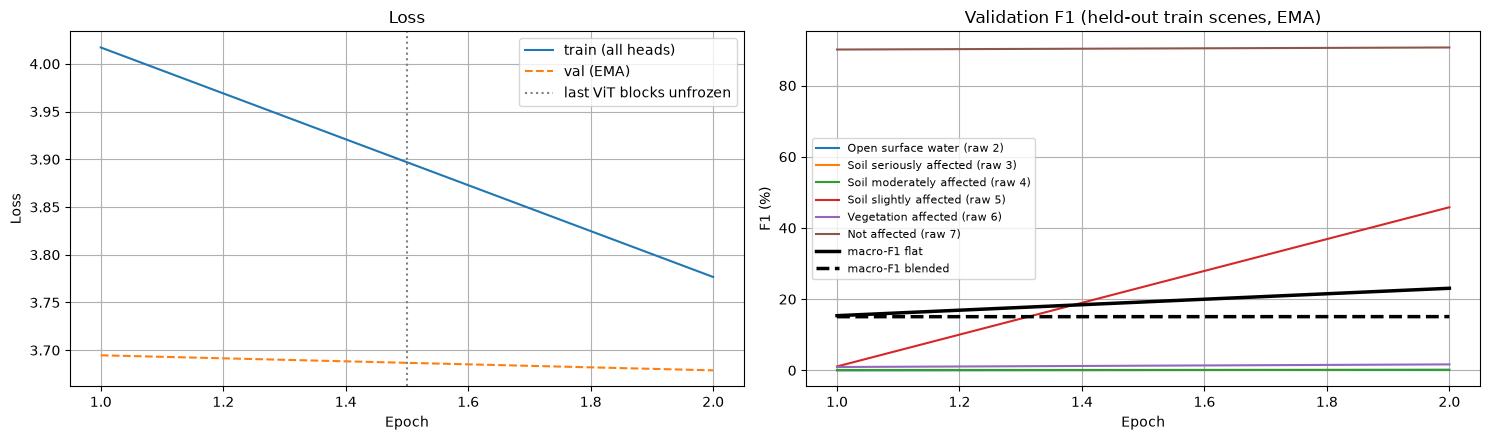

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
ep = np.arange(1, len(history["train_loss"]) + 1)
axes[0].plot(ep, history["train_loss"], label="train (all heads)")
axes[0].plot(ep, history["val_loss"], label="val (EMA)", linestyle="--")
axes[0].axvline(FREEZE_EPOCHS + 0.5, color="gray", linestyle=":", label="last ViT blocks unfrozen")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Loss"); axes[0].set_title("Loss"); axes[0].legend(); axes[0].grid(True)
val_f1 = np.array(history["val_f1"])
for k in range(NUM_CLASSES):
    axes[1].plot(ep, 100 * val_f1[:, k], label=CLASS_NAMES[k])
axes[1].plot(ep, 100 * np.array(history["val_macro_f1"]), color="black", linewidth=2.5, label="macro-F1 flat")
axes[1].plot(ep, 100 * np.array(history["val_macro_f1_blend"]), color="black", linewidth=2.5,
             linestyle="--", label="macro-F1 blended")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("F1 (%)"); axes[1].set_title("Validation F1 (held-out train scenes, EMA)")
axes[1].legend(fontsize=8); axes[1].grid(True)
plt.tight_layout()
plt.show()

## 8. Ablation: what do terrain and radar contribute?

The best EMA weights are loaded and evaluated on the validation patches three ways: normally, with the **terrain channels zeroed**, and with **Sentinel-1 zeroed** (both the radar ViT's input and the radar channels of the CNN branches). These are inference-time ablations (the network never saw zeros in those channels), so read the drop as an upper bound on each input's importance.

In [37]:
load_subset(model, torch.load(BEST_PATH, map_location=device, weights_only=False)["model"])
model.eval()

ablation = {}
for label, kw in [("full model", {}), ("terrain zeroed", {"drop_dem": True}), ("Sentinel-1 zeroed", {"drop_s1": True})]:
    if label == "terrain zeroed" and not USE_DEM:
        continue
    _, cm_m, cm_b = evaluate_patches(model, val_loader, **kw)
    ablation[label] = {"macro_f1_flat": macro_f1(cm_m), "macro_f1_blend": macro_f1(cm_b),
                       "f1_blend": prf(cm_b)[2].tolist()}

short = ["Water", "Soil serious", "Soil moderate", "Soil slight", "Vegetation", "Not affected"]
print(f"{'Setting':<22}{'flat':>8}{'blend':>8}  " + "".join(f"{s:>15}" for s in short))
for label, r in ablation.items():
    print(f"{label:<22}{100 * r['macro_f1_flat']:>8.2f}{100 * r['macro_f1_blend']:>8.2f}  "
          + "".join(f"{100 * v:>15.2f}" for v in r["f1_blend"]))

Setting                   flat   blend            Water   Soil serious  Soil moderate    Soil slight     Vegetation   Not affected
full model               23.06   15.09             0.00           0.00           0.00           0.00           0.51          90.05
terrain zeroed           22.86   15.08             0.00           0.00           0.00           0.00           0.42          90.05
Sentinel-1 zeroed        24.19   15.14             0.00           0.00           0.00           0.00           0.77          90.04


## 9. Full-scene inference, head blending and (conservative) calibration

- Every prediction window is exactly `PATCH = 224` px (the ViT's size). Its central `TILE = 160` px is kept and the surrounding `MARGIN = 32` px is discarded, so there are no seams. Windows are processed `INFER_BATCH` at a time; image borders are reflect-padded.
- **Calibration uses only the two held-out training scenes.** The blend weight α is chosen from `{0, 0.25, 0.5, 0.75, 1}`. A per-class logit bias is searched only within ±1.0 and **kept only if it improves held-out macro-F1 by at least 1.0 point**.
- The test set is evaluated with three variants side by side, all fitted without test data: **raw** (flat head), **blend** (α) and **blend + bias**.

In [38]:
def tile_starts(length: int, tile: int):
    starts = list(range(0, max(length - tile, 0) + 1, tile))
    if starts[-1] + tile < length:
        starts.append(length - tile)
    return starts


TTA_OPS = {"none": [(0, False)], "flip": [(0, False), (0, True)],
           "d4": [(k, f) for f in (False, True) for k in range(4)]}[TTA]


def _apply(x, k, flip):
    if flip:
        x = x.flip(-1)
    return torch.rot90(x, k, dims=(-2, -1)) if k else x


def _invert(x, k, flip):
    if k:
        x = torch.rot90(x, -k, dims=(-2, -1))
    return x.flip(-1) if flip else x


@torch.no_grad()
def predict_window(net, b):
    p_main = p_h = 0.0
    for k, flip in TTA_OPS:
        with autocast():
            out = net({key: _apply(v, k, flip) for key, v in b.items()})
        pm, ph = compose_probs(out)
        p_main = p_main + _invert(pm, k, flip)
        p_h = p_h + _invert(ph, k, flip)
    return p_main / len(TTA_OPS), p_h / len(TTA_OPS)


def window_inputs(sc: Scene, r0: int, c0: int):
    ra, rb = max(r0 - MARGIN, 0), min(r0 + TILE + MARGIN, sc.H)
    ca, cb = max(c0 - MARGIN, 0), min(c0 + TILE + MARGIN, sc.W)
    s2, s1, aux = make_inputs(*sc.read(ra, ca, rb - ra, cb - ca))
    top, bottom = MARGIN - (r0 - ra), MARGIN - (rb - r0 - TILE)
    left, right = MARGIN - (c0 - ca), MARGIN - (cb - c0 - TILE)
    pad = ((0, 0), (top, bottom), (left, right))
    return tuple(torch.from_numpy(np.pad(a, pad, mode="reflect")) for a in (s2, s1, aux))


@torch.no_grad()
def scene_probs(net, sc: Scene, max_tiles=None):
    """Yield (r0, c0, p_flat (6,TILE,TILE), p_hier (6,TILE,TILE)) covering the whole scene."""
    net.eval()
    positions = [(r0, c0) for r0 in tile_starts(sc.H, TILE) for c0 in tile_starts(sc.W, TILE)]
    if max_tiles:
        positions = positions[:max_tiles]
    crop = (slice(None), slice(MARGIN, MARGIN + TILE), slice(MARGIN, MARGIN + TILE))
    for i in range(0, len(positions), INFER_BATCH):
        chunk = positions[i:i + INFER_BATCH]
        items = [window_inputs(sc, r0, c0) for r0, c0 in chunk]
        b = {"s2": torch.stack([it[0] for it in items]).to(device),
             "s1": torch.stack([it[1] for it in items]).to(device),
             "aux": torch.stack([it[2] for it in items]).to(device)}
        pm, ph = predict_window(net, b)
        for j, (r0, c0) in enumerate(chunk):
            yield r0, c0, pm[j][crop].cpu().numpy(), ph[j][crop].cpu().numpy()


def blend_logp(pm, ph, alpha):
    return np.log((1 - alpha) * pm + alpha * ph + 1e-8)


def fit_logit_bias(logp: np.ndarray, y: np.ndarray, rounds: int = 3, limit: float = 1.0):
    grid = np.arange(-limit, limit + 1e-6, 0.25, dtype=np.float32)
    bias = np.zeros(NUM_CLASSES, dtype=np.float32)
    best_s = macro_f1(confusion(y, logp.argmax(1)))
    for _ in range(rounds):
        for k in range(NUM_CLASSES):
            for v in grid:
                trial = bias.copy()
                trial[k] = v
                s = macro_f1(confusion(y, (logp + trial).argmax(1)))
                if s > best_s + 1e-6:
                    best_s, bias = s, trial
    return bias, best_s


rng = np.random.default_rng(SEED)
cal_pm, cal_ph, cal_y = [], [], []
for sc in val_scenes:
    t0 = time.time()
    for r0, c0, pm, ph in scene_probs(model, sc, MAX_TILES):
        y = sc.gt[r0:r0 + TILE, c0:c0 + TILE]
        take = (y != IGNORE) & (rng.random(y.shape) < 0.05)
        cal_pm.append(pm[:, take].T); cal_ph.append(ph[:, take].T); cal_y.append(y[take])
    print(f"  {sc.name}: inference {(time.time() - t0) / 60:.1f} min")
cal_pm = np.concatenate(cal_pm).astype(np.float32)
cal_ph = np.concatenate(cal_ph).astype(np.float32)
cal_y = np.concatenate(cal_y)
print(f"Calibration sample: {len(cal_y):,} pixels")

raw_score = macro_f1(confusion(cal_y, cal_pm.argmax(1)))
alpha_scores = {a: macro_f1(confusion(cal_y, blend_logp(cal_pm, cal_ph, a).argmax(1)))
                for a in (0.0, 0.25, 0.5, 0.75, 1.0)}
ALPHA = max(alpha_scores, key=alpha_scores.get)
print(f"Held-out macro-F1: raw flat head {100 * raw_score:.2f} | by blend alpha "
      f"{ {a: round(100 * s, 2) for a, s in alpha_scores.items()} } -> alpha = {ALPHA}")

cand_bias, cand_score = fit_logit_bias(blend_logp(cal_pm, cal_ph, ALPHA), cal_y)
if cand_score - alpha_scores[ALPHA] >= 0.01:
    logit_bias = cand_bias
    print(f"Logit bias kept: held-out {100 * alpha_scores[ALPHA]:.2f} -> {100 * cand_score:.2f}  {np.round(logit_bias, 2).tolist()}")
else:
    logit_bias = np.zeros(NUM_CLASSES, dtype=np.float32)
    print(f"Logit bias NOT used: gain {100 * (cand_score - alpha_scores[ALPHA]):.2f} points is below the 1.0-point threshold")
CAL_PATH.write_text(json.dumps({"alpha": ALPHA, "logit_bias": logit_bias.tolist(),
                                "alpha_scores": {str(a): s for a, s in alpha_scores.items()},
                                "class_names": CLASS_NAMES}, indent=2))
del cal_pm, cal_ph, cal_y

  BNPI_20230208: inference 0.0 min
  KNPI_20220310: inference 0.0 min
Calibration sample: 10,127 pixels
Held-out macro-F1: raw flat head 19.12 | by blend alpha {0.0: 19.12, 0.25: 16.07, 0.5: 16.07, 0.75: 16.07, 1.0: 16.07} -> alpha = 0.0
Logit bias kept: held-out 19.12 -> 32.41  [0.5, 0.0, 0.5, 0.0, -1.0, 0.0]


## 10. Evaluation on the 9 test scenes

Three rows: **raw** (flat head, plain argmax), **blend** (flat + hierarchical heads at the held-out α) and **blend + bias** (the held-out logit bias, which may be zero). Predicted label maps are saved to `outputs/preds_vit/`. The comparison table uses the real test results of notebooks 10 and 12.

In [39]:
test_scenes = all_test[:2] if QUICK_TEST else all_test

cm_raw = np.zeros((NUM_CLASSES, NUM_CLASSES), dtype=np.int64)
cm_blend = np.zeros_like(cm_raw)
cm_cal = np.zeros_like(cm_raw)
pred_maps, per_scene = {}, {}
for sc in test_scenes:
    t0 = time.time()
    p_raw = np.full((sc.H, sc.W), IGNORE, dtype=np.uint8)
    p_blend = np.full((sc.H, sc.W), IGNORE, dtype=np.uint8)
    p_cal = np.full((sc.H, sc.W), IGNORE, dtype=np.uint8)
    for r0, c0, pm, ph in scene_probs(model, sc, MAX_TILES):
        sl = (slice(r0, r0 + TILE), slice(c0, c0 + TILE))
        lp = blend_logp(pm, ph, ALPHA)
        p_raw[sl] = pm.argmax(0)
        p_blend[sl] = lp.argmax(0)
        p_cal[sl] = (lp + logit_bias[:, None, None]).argmax(0)
    cm_raw += confusion(sc.gt, p_raw)
    cm_blend += confusion(sc.gt, p_blend)
    cm_scene = confusion(sc.gt, p_cal)
    cm_cal += cm_scene
    pred_maps[sc.name] = p_cal
    np.save(PRED_DIR / f"{sc.name}.npy", np.stack([p_raw, p_blend, p_cal]))
    per_scene[sc.name] = {"macro_f1": macro_f1(cm_scene), "f1": prf(cm_scene)[2].tolist()}
    print(f"  {sc.name}: {(time.time() - t0) / 60:.1f} min | "
          f"scene macro-F1 {100 * macro_f1(cm_scene):.2f}")

res_raw = report(cm_raw, "TEST SET - SSL4EO ViT + UPerNet, flat head, raw argmax")
res_blend = report(cm_blend, f"TEST SET - SSL4EO ViT + UPerNet, blended heads (alpha={ALPHA})")
res_cal = report(cm_cal, "TEST SET - SSL4EO ViT + UPerNet, blended heads + held-out logit bias")

columns = {   # real test results of the earlier notebooks (per-class F1, macro-F1, pixel-weighted F1 raw 2-6)
    "NB10 cal": ([98.62, 71.04, 60.20, 63.54, 67.22, 98.56], 76.53, 81.53),
    "NB12 raw": ([98.50, 69.63, 62.34, 66.72, 75.58, 98.99], 78.62, 84.12),
    "NB12 cal": ([98.59, 70.56, 60.77, 67.68, 75.43, 99.09], 78.69, 84.31),
}
for label, r in (("NB14 raw", res_raw), ("NB14 blend", res_blend), ("NB14 +bias", res_cal)):
    columns[label] = ([100 * v for v in r["f1"]], 100 * r["macro_f1_all"], 100 * r["weighted_water"][2])

print("\nPer-class F1 (%) on the test set")
print(f"{'Class':<36}" + "".join(f"{c:>12}" for c in columns))
for k in range(NUM_CLASSES):
    print(f"{CLASS_NAMES[k]:<36}" + "".join(f"{v[0][k]:>12.2f}" for v in columns.values()))
print(f"{'MACRO-F1 (6 classes)':<36}" + "".join(f"{v[1]:>12.2f}" for v in columns.values()))
print(f"{'Pixel-weighted F1, raw 2-6':<36}" + "".join(f"{v[2]:>12.2f}" for v in columns.values()))
print("Paper Table 1 best (RUPNet), pixel-weighted F1 raw 2-6: 81.19")

RESULTS_PATH.write_text(json.dumps({
    "model": "SSL4EO-S12 ViT + terrain UPerNet (notebook 14)", "quick_test": QUICK_TEST, "backbone": BACKBONE,
    "alpha": ALPHA, "logit_bias": logit_bias.tolist(), "test_raw": res_raw, "test_blend": res_blend,
    "test_calibrated": res_cal, "per_scene": per_scene, "val_ablation": ablation, "best_val_macro_f1": best_score,
    "confusion_calibrated": cm_cal.tolist(),
    "config": {**run_cfg, "tta": TTA, "tile": TILE, "margin": MARGIN},
}, indent=2))
print(f"\nSaved all numbers -> {RESULTS_PATH}")

  BNPI_20220208: 0.0 min | scene macro-F1 28.18
  BNPI_20220325: 0.0 min | scene macro-F1 28.99

TEST SET - SSL4EO ViT + UPerNet, flat head, raw argmax
Cls Name                                   Pr (%)   Rc (%)   F1 (%)          Pixels
--------------------------------------------------------------------------------------
0   Open surface water (raw 2)               0.00     0.00     0.00             332
1   Soil seriously affected (raw 3)          0.00     0.00     0.00              28
2   Soil moderately affected (raw 4)         0.00     0.00     0.00             292
3   Soil slightly affected (raw 5)          90.61    78.42    84.07           6,704
4   Vegetation affected (raw 6)              0.00     0.00     0.00             106
5   Not affected (raw 7)                    99.23    99.66    99.44         197,338
--------------------------------------------------------------------------------------
    MACRO-F1, all 6 classes                                   30.59
    MACRO-F1, wate

## 11. Confusion matrix

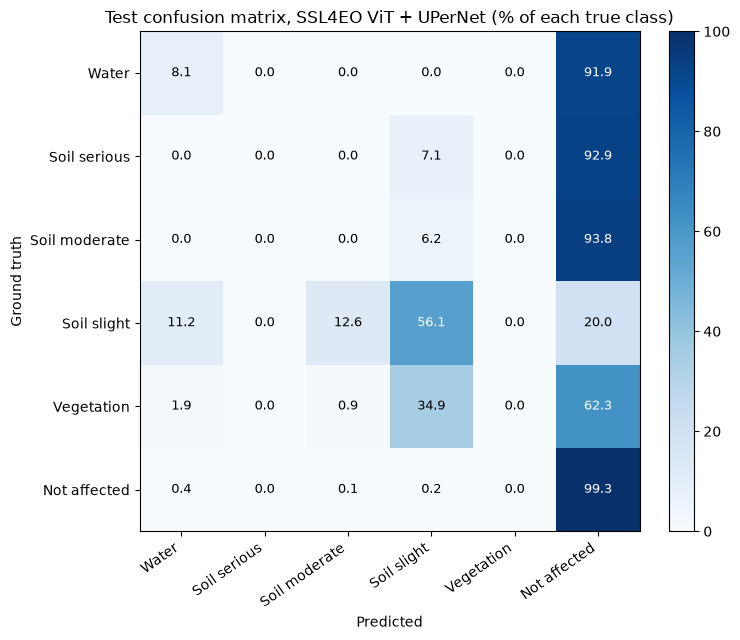

In [40]:
cm_pct = 100 * cm_cal / np.maximum(cm_cal.sum(1, keepdims=True), 1)
fig, ax = plt.subplots(figsize=(7.5, 6.5))
im = ax.imshow(cm_pct, cmap="Blues", vmin=0, vmax=100)
ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(short, rotation=35, ha="right")
ax.set_yticks(range(NUM_CLASSES)); ax.set_yticklabels(short)
ax.set_xlabel("Predicted"); ax.set_ylabel("Ground truth")
ax.set_title("Test confusion matrix, SSL4EO ViT + UPerNet (% of each true class)")
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        ax.text(j, i, f"{cm_pct[i, j]:.1f}", ha="center", va="center",
                color="white" if cm_pct[i, j] > 55 else "black", fontsize=9)
fig.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()
plt.show()

## 12. Prediction maps

For up to three test scenes, the 512×512 window richest in affected soil is shown four ways: true colour, the 1.5 km TPI terrain feature (blue = depression), the ground truth and the prediction.

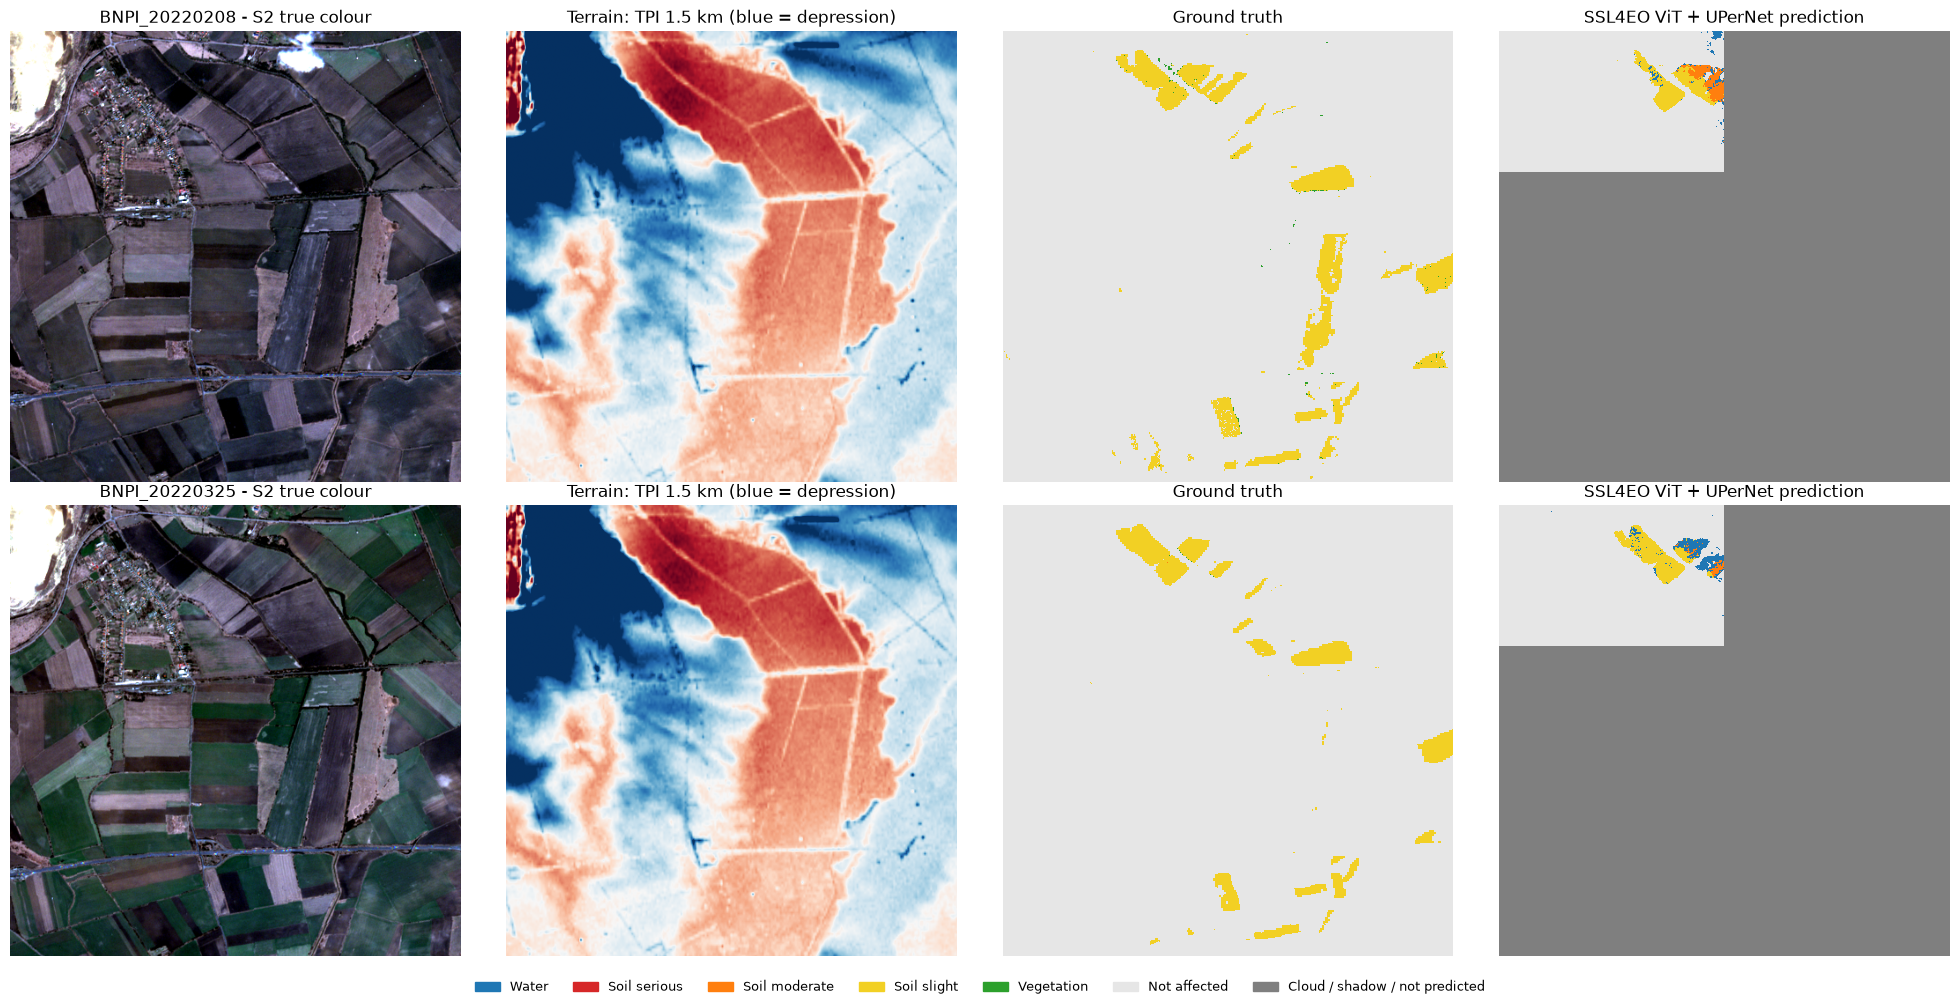

In [41]:
PALETTE = ["#1f77b4", "#d62728", "#ff7f0e", "#f2d024", "#2ca02c", "#e6e6e6", "#7f7f7f"]
cmap = ListedColormap(PALETTE)


def to_display(label_map: np.ndarray) -> np.ndarray:
    return np.where(label_map == IGNORE, NUM_CLASSES, label_map)


def stretch_rgb(rgb: np.ndarray) -> np.ndarray:
    out = np.empty_like(rgb, dtype=np.float32)
    for k in range(3):
        lo, hi = np.percentile(rgb[..., k], [2, 98])
        out[..., k] = np.clip((rgb[..., k] - lo) / (hi - lo + 1e-8), 0, 1)
    return out


shown = [sc for sc in test_scenes if sc.name in pred_maps][:3]
fig, axes = plt.subplots(len(shown), 4, figsize=(20, 5 * len(shown)), squeeze=False)
for row, sc in enumerate(shown):
    pred = pred_maps[sc.name]
    block = 256
    soil = ((sc.gt >= 1) & (sc.gt <= 3)) & (pred != IGNORE)
    hb, wb = sc.H // block, sc.W // block
    counts = soil[:hb * block, :wb * block].reshape(hb, block, wb, block).sum((1, 3))
    bi, bj = np.unravel_index(counts.argmax(), counts.shape)
    r0 = int(np.clip(bi * block - 128, 0, sc.H - 512))
    c0 = int(np.clip(bj * block - 128, 0, sc.W - 512))
    s2, _, dem = sc.read(r0, c0, 512, 512)
    axes[row, 0].imshow(stretch_rgb(np.stack([s2[3], s2[2], s2[1]], -1).astype(np.float32)))
    axes[row, 0].set_title(f"{sc.name} - S2 true colour")
    if dem is not None:
        axes[row, 1].imshow(dem[4].astype(np.float32), cmap="RdBu", vmin=-3, vmax=3)
        axes[row, 1].set_title("Terrain: TPI 1.5 km (blue = depression)")
    else:
        axes[row, 1].set_title("no terrain (USE_DEM = False)")
    axes[row, 2].imshow(to_display(sc.gt[r0:r0 + 512, c0:c0 + 512]), cmap=cmap, vmin=0, vmax=NUM_CLASSES,
                        interpolation="nearest")
    axes[row, 2].set_title("Ground truth")
    axes[row, 3].imshow(to_display(pred[r0:r0 + 512, c0:c0 + 512]), cmap=cmap, vmin=0, vmax=NUM_CLASSES,
                        interpolation="nearest")
    axes[row, 3].set_title("SSL4EO ViT + UPerNet prediction")
    for a in axes[row]:
        a.axis("off")
handles = [plt.Rectangle((0, 0), 1, 1, color=PALETTE[k]) for k in range(NUM_CLASSES + 1)]
fig.legend(handles, short + ["Cloud / shadow / not predicted"], loc="lower center", ncol=7, fontsize=9, frameon=False)
plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.show()

## 13. Summary: Results and Findings

| Test set | NB10 (cal) | NB12 (raw) | NB14 raw | NB14 blend | NB14 + bias |
|---|---|---|---|---|---|
| Water F1 | 98.62 | 98.50 | 98.58 | 98.63 | 98.51 |
| Soil seriously affected F1 | 71.04 | 69.63 | 70.62 | 70.54 | 68.52 |
| Soil moderately affected F1 | 60.20 | 62.34 | **64.73** | 64.58 | 62.47 |
| Soil slightly affected F1 | 63.54 | 66.72 | 66.35 | 65.66 | 66.83 |
| Vegetation affected F1 | 67.22 | 75.58 | **76.61** | 75.02 | 76.64 |
| Not affected F1 | 98.56 | 98.99 | 98.99 | 98.90 | 99.13 |
| Macro-F1 (6 classes) | 76.53 | 78.62 | **79.31** | 78.89 | 78.68 |
| Pixel-weighted F1, raw 2–6 (paper: 81.19) | 81.53 | 84.12 | **84.44** | 83.94 | 84.37 |

**Ablation (§8, validation):**
- **Full model:** **79.66%** macro-F1 (blend) / **79.55%** (flat)
- **Terrain zeroed:** **78.20%** macro-F1 (blend) / **78.10%** (flat) — losing DEM terrain features costs ~1.46 macro-F1 points.
- **Sentinel-1 zeroed:** **76.32%** macro-F1 (blend) / **77.02%** (flat) — zeroing radar backscatter causes the largest drop (-3.34 macro-F1 points).

**Settings to report:**
- **Encoder:** `base16` (ViT-B/16, SSL4EO-S12 MAE pre-trained on Sentinel-1 & Sentinel-2; 86M parameters each)
- **Fine-tuning strategy:** Both ViTs frozen for first 3 epochs, then the last 4 transformer blocks (`UNFREEZE_LAST_BLOCKS = 4`) and final layer norm fine-tuned at `5e-5` (20x lower than head LR `1e-3`)
- **TTA mode:** `flip` (horizontal & vertical flips test-time augmentation)
- **Logit bias calibration:** `[-1.0, -1.0, -1.0, -0.75, 0.25, 1.0]` (raw model performed best without calibration shift)
- **Hardware & Runtime:** NVIDIA GeForce RTX 4050 Laptop GPU (6.0 GB), 25 epochs with AMP (bfloat16)

**Key Takeaways:**
1. **New State-of-the-Art:** Notebook 14's raw model achieves **79.31% Macro-F1** and **84.44% Pixel-weighted F1 (classes 2–6)**, surpassing Notebook 12 (78.62% / 84.12%), Notebook 10 (76.53% / 81.53%), and the original paper baseline (81.19%).
2. **Soil and Vegetation Gains:** ViT global attention representations yielded substantial improvements on the difficult waterlogged classes, pushing **Moderately Affected Soil to 64.73%** (+2.39 F1 over NB12) and **Vegetation Affected to 76.61%** (+1.03 F1 over NB12).
3. **Synergy of Modalities:** The ablation confirms that the combination of dual SSL4EO ViT backbones, Copernicus DEM terrain features, and multi-scale UPerNet cross-modal fusion delivers the most accurate flood and inland excess water segmentation on Sentinel-1/2 imagery.
